# Multi-session analyses — R4/R5/R6

Cross-session views of pipeline performance. Two sections:

1. **SLEAP-only** — every session with `triang_keys_3D.npy` + `frame_mapping.csv`.
   Trends per rat across sessions: rear counts, matches inside/outside the
   port-exclusion zone (overall, first 5 min, rest), dropped frames, rear
   duration stats, % rears matched, % online triggers followed by a lick
   within 10 s.

2. **SLEAP + DANNCE** — subset of section 1 that also has processed
   `sleap_dannce_keys.*`. For each session: rebuild SLEAP and DANNCE templates
   from the in-session SLEAP matches, score overlap (SLEAP-only / DANNCE-only /
   both), plus calibration reprojection residuals, per-session keypoint
   distance, per-session PC MSE (raw + per-modality-mean-subtracted).

Code is mostly lifted verbatim from `session_review_2026_06.ipynb` (section 1)
and `single_session.ipynb` (section 2) so the per-session numbers match.

In [188]:
# ----- CONFIG -----
RATS        = ['R4', 'R5', 'R6']
DATE_START  = '2026_06_05'        # inclusive
DATE_END    = '2026_12_31'        # inclusive
DATA_ROOT   = '/home/yutaka-sprague/olveczky_lab/Lab/CLIRB/data'
SLEAP_HZ    = 20
WARMUP_FRAMES   = 5 * 60 * SLEAP_HZ   # 5 min @ 20 Hz
LICK_WINDOW_MS  = 10_000              # 'lick within 10 s of online trigger'
N_COMPONENTS    = 2                   # matches the online rule
TEMPLATE_LEN    = 30                  # matches the online rule (1.5 s @ 20 Hz)
# -------------------

import os, sys, glob, warnings
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.ndimage import median_filter

sys.path.insert(0, '.')
from skeleton import normalize_skeleton_batch, project_to_pcs
from data_io import (load_sleap_dannce_keys, load_aligned_data,
                     load_opcon_events, load_calibration, load_template)
from projection import project_3d_to_2d_for_camera
import session_cache as sc

warnings.filterwarnings('ignore', category=RuntimeWarning)
plt.rcParams['figure.dpi'] = 110
%matplotlib inline

RAT_COLOR = {'R4': '#1f77b4', 'R5': '#ff7f0e', 'R6': '#2ca02c'}


## Section 1 — SLEAP-only cross-session analyses

In [189]:
RESULTS = {}
_session_cache = {}

In [190]:
def discover_sessions(rats=RATS, date_start=DATE_START, date_end=DATE_END):
    out = []
    for rat in rats:
        rat_dir = os.path.join(DATA_ROOT, rat)
        if not os.path.isdir(rat_dir):
            continue
        for s in sorted(os.listdir(rat_dir)):
            sd = os.path.join(rat_dir, s, 'sleap')
            if not os.path.isdir(sd):
                continue
            if not (date_start <= s[:10] <= date_end):
                continue
            if not (os.path.isfile(os.path.join(sd, 'triang_keys_3D.npy'))
                    and os.path.isfile(os.path.join(sd, 'frame_mapping.csv'))):
                continue
            out.append((rat, s))
    return out


def _find_template_file(sleap_dir, rat):
    cand = sorted(glob.glob(os.path.join(sleap_dir, f'{rat}_template_*.npz')))
    return cand[0] if cand else None


def _find_port_location(sleap_dir):
    m = sorted(glob.glob(os.path.join(sleap_dir, 'calibration', '*', 'water_port_location.npy')))
    return m[0] if m else None



def load_session(rat, session):
    key = (rat, session)
    if key in _session_cache:
        return _session_cache[key]
    sleap_dir = os.path.join(DATA_ROOT, rat, session, 'sleap')
    out = {'rat': rat, 'session': session, 'sleap_dir': sleap_dir}
    try:
        # Raw inputs via the local disk cache (session_cache.py). First run reads
        # SMB + writes the cache; later runs read the local .npz.
        _c = sc.get_raw_session(rat, session, want_dual=False)
        if _c is None:
            print(f'  {rat}/{session}: raw inputs missing/corrupt — skipping.')
            return None
        out['triang_3d'] = _c['triang_3d']
        # Reconstruct the frame_mapping DataFrame with the two columns cell 6 uses.
        out['frame_mapping'] = pd.DataFrame({
            'cam0_frame': _c['frame_mapping_cam0'],
            'cam0_acquisition_time': _c['cam0_acq_time']})
        out['behavior_times'] = None  # not consumed downstream
        out['has_task_log'] = bool(_c['has_task_log'])
        # cell 6 only reads log.loc[log['triggered']==1, 'frame']; reconstruct it.
        out['behavior_log'] = (pd.DataFrame({'frame': _c['behavior_log_frames'],
                                             'triggered': 1})
                               if out['has_task_log'] else None)
        tmpl_path = _find_template_file(sleap_dir, rat)
        if tmpl_path is None:
            tmpl_path = os.path.join(DATA_ROOT, rat, 'templates', f'{rat}_template_1.npz')
        if not os.path.isfile(tmpl_path):
            print(f'  {rat}/{session}: no template found — skipping')
            return None
        z = np.load(tmpl_path, allow_pickle=True)
        out['template'] = {k: z[k] for k in z.files}
        out['template_file'] = tmpl_path
        _pxy = np.asarray(_c['port_xy']).ravel()[:3]
        out['port_xy'] = _pxy if _pxy.size and np.isfinite(_pxy).all() else None
        out['min_port_distance'] = float(_c['min_port_distance'])
    except Exception as e:
        print(f'  {rat}/{session}: load failed — {e!r}')
        return None
    _session_cache[key] = out
    return out


SESSIONS = discover_sessions()
print(f'discovered {len(SESSIONS)} sessions across {RATS}')


discovered 106 sessions across ['R4', 'R5', 'R6']


### (optional) Warm the local cache in one SMB pass

Run this cell **once on a fresh cache** to pre-build every session's local
cache (triang + SLEAP/DANNCE keys + `sleap_keys_2D`) in a single SMB read per
session. After it finishes, the whole notebook runs from the local cache with
no SMB reads. Skipping this cell also works — the sections below build the
cache lazily, but first-run sessions with DANNCE data get read from SMB twice
(once for Section 1, once when Section 2 upgrades them to dual). See
`session_cache.py`.


In [191]:
# One-pass warm of the local cache (want_dual=True builds the COMPLETE cache:
# triang + sleap_keys_3D + dannce_keys_3D + sleap_keys_2D). Safe to re-run --
# already-cached, up-to-date sessions are skipped. Comment out to skip.
sc.warm_cache(SESSIONS, want_dual=True)


  built R4/2026_06_05_1 (51.1 MB, dual=True)
  built R4/2026_06_08_1 (51.1 MB, dual=True)
  built R4/2026_06_09_1 (51.1 MB, dual=True)
  built R4/2026_06_11_1 (114.1 MB, dual=True)
  built R4/2026_06_12_1 (114.2 MB, dual=True)
  built R4/2026_06_15_1 (88.6 MB, dual=True)
  built R4/2026_06_16_1 (88.9 MB, dual=True)
  built R4/2026_06_17_1 (88.9 MB, dual=True)
  built R4/2026_06_18_1 (88.9 MB, dual=True)
  built R4/2026_06_18_2 (88.9 MB, dual=True)
  built R4/2026_06_19_1 (47.0 MB, dual=False)
  built R4/2026_06_20_1 (88.9 MB, dual=True)
  built R4/2026_06_22_1 (47.7 MB, dual=False)
  built R4/2026_06_22_2 (88.9 MB, dual=True)
  built R4/2026_06_23_1 (88.9 MB, dual=True)
  built R4/2026_06_23_2 (88.9 MB, dual=True)
  built R4/2026_06_24_1 (88.9 MB, dual=True)
  built R4/2026_06_25_1 (88.9 MB, dual=True)
  built R4/2026_06_25_2 (88.9 MB, dual=True)
  built R4/2026_06_26_1 (47.0 MB, dual=False)
  built R4/2026_06_26_2 (88.9 MB, dual=True)
  built R4/2026_06_28_1 (63.7 MB, dual=True)
  bui

In [192]:
def _causal_median_5_kp(triang):
    pad = 4
    padded = np.concatenate([np.repeat(triang[:1], pad, axis=0), triang], axis=0)
    T = triang.shape[0]
    widx = np.arange(T)[:, None] + np.arange(5)[None, :]
    return np.median(padded[widx], axis=1).astype(np.float32)


def project_session_to_pcs(sd):
    """kp -> PC projection, matching the order the online rule uses
    (z-flip, normalize, median, center, project).
    """
    triang = sd['triang_3d'].astype(np.float32)
    flipped = triang.copy()
    flipped[:, :, 2] = -flipped[:, :, 2]
    rotated, _, _ = normalize_skeleton_batch(flipped)
    rotated_med = _causal_median_5_kp(rotated)
    flat = rotated_med.reshape(rotated_med.shape[0], -1)
    tmpl = sd['template']
    centered = flat - tmpl['feature_means']
    return centered @ tmpl['pc_weights'].T


def replay_rule_offline(sd, accepted_errors=3):
    """Return (match_frames_cam0, num_outside_per_frame, pcs_full)."""
    tmpl = sd['template']
    pcs_to_use = np.asarray(tmpl['pcs_to_use']).ravel().astype(int)
    template = tmpl['template'][:, :len(pcs_to_use)]
    bounds_arr = tmpl['bounds_to_use'] if 'bounds_to_use' in tmpl else (
        np.tile(tmpl['feature_stds'][pcs_to_use] * float(tmpl['bounds']),
                (template.shape[0], 1)))
    pcs_full = project_session_to_pcs(sd)
    pcs = pcs_full[:, pcs_to_use]
    T, _ = pcs.shape
    win = template.shape[0]
    if T < win:
        return np.array([], dtype=int), np.full(T, np.nan), pcs_full
    arange_t = np.arange(win, dtype=np.int64)
    base = np.arange(T - win + 1, dtype=np.int64)[:, None]
    windows = pcs[base + arange_t]
    above = windows >= (template + bounds_arr)
    below = windows <= (template - bounds_arr)
    outside_count = (above | below).reshape(windows.shape[0], -1).sum(axis=1)
    num_outside = np.full(T, np.nan)
    num_outside[win - 1:] = outside_count
    matches, last = [], -win
    for t in range(win - 1, T):
        if outside_count[t - (win - 1)] <= accepted_errors and (t - last) >= win:
            matches.append(t)
            last = t
    return np.array(matches, dtype=int), num_outside, pcs_full


In [193]:
def compute_session_analysis(sd, accepted_errors=3, port_match_tol_frames=5):
    fm = sd['frame_mapping']
    pf_to_cam0 = fm['cam0_frame'].to_numpy(dtype=int)
    pf_to_acq  = fm['cam0_acquisition_time'].to_numpy(dtype=float)

    triang = sd['triang_3d']
    if sd['has_task_log']:
        log = sd['behavior_log']
        online_trig_pf = log.loc[log['triggered'] == 1, 'frame'].to_numpy(dtype=int)
        online_trig_pf = online_trig_pf[online_trig_pf < len(pf_to_cam0)]
        online_trig_cam0 = pf_to_cam0[online_trig_pf]
        online_trig_acq  = pf_to_acq[online_trig_pf]
    else:
        online_trig_pf = np.array([], dtype=int)
        online_trig_cam0 = np.array([], dtype=int)
        online_trig_acq  = np.array([], dtype=float)

    offline_match_cam0, num_outside_cam0, pcs_full = replay_rule_offline(
        sd, accepted_errors=accepted_errors)

    if sd['port_xy'] is not None:
        port_xy = np.asarray(sd['port_xy']).ravel()[:2]
        com_xy = triang.mean(axis=1)[:, :2]
        port_dist = np.linalg.norm(com_xy - port_xy[None, :], axis=1)
    else:
        port_dist = np.full(len(triang), np.nan)

    offline_match_dist = port_dist[offline_match_cam0] if len(offline_match_cam0) else np.array([])

    # Online/offline pairing (only meaningful for task sessions).
    onset_arr, off_arr = online_trig_cam0, offline_match_cam0
    both = np.zeros(len(onset_arr), dtype=bool)
    off_matched = np.zeros(len(off_arr), dtype=bool)
    if len(onset_arr) and len(off_arr):
        for i, f in enumerate(onset_arr):
            diffs = np.abs(off_arr - f)
            j = int(np.argmin(diffs))
            if diffs[j] <= port_match_tol_frames and not off_matched[j]:
                both[i] = True
                off_matched[j] = True
    intersect = onset_arr[both]

    n_processed = len(pf_to_cam0)
    n_cam0_max = int(pf_to_cam0.max()) + 1 if n_processed else 0
    drop_rate = 1.0 - (n_processed / max(n_cam0_max, 1))

    return {
        'sd': sd,
        'online_trig_pf': online_trig_pf,
        'online_trig_cam0': online_trig_cam0,
        'online_trig_acq': online_trig_acq,
        'offline_match_cam0': offline_match_cam0,
        'offline_match_dist': offline_match_dist,
        'num_outside_cam0': num_outside_cam0,
        'pcs_full': pcs_full,
        'port_dist': port_dist,
        'intersect_cam0': intersect,
        'drop_rate': drop_rate,
    }

for rat, s in SESSIONS:
    if not (rat, s) in RESULTS.keys():
        print(f'Loading {rat}/{s}')
        sd = load_session(rat, s)
        if sd is None:
            continue
        RESULTS[(rat, s)] = compute_session_analysis(sd)
    else:
        print(f'{rat}/{s} already loaded')
print(f'analysed {len(RESULTS)} sessions')


Loading R4/2026_06_05_1
Loading R4/2026_06_08_1
Loading R4/2026_06_09_1
Loading R4/2026_06_11_1
Loading R4/2026_06_12_1
Loading R4/2026_06_15_1
Loading R4/2026_06_16_1
Loading R4/2026_06_17_1
Loading R4/2026_06_18_1
Loading R4/2026_06_18_2
Loading R4/2026_06_19_1
Loading R4/2026_06_20_1
Loading R4/2026_06_22_1
Loading R4/2026_06_22_2
Loading R4/2026_06_23_1
Loading R4/2026_06_23_2
Loading R4/2026_06_24_1
Loading R4/2026_06_25_1
Loading R4/2026_06_25_2
Loading R4/2026_06_26_1
Loading R4/2026_06_26_2
Loading R4/2026_06_28_1
Loading R4/2026_06_29_1
Loading R4/2026_06_29_2
Loading R4/2026_06_30_1
Loading R4/2026_06_30_2
Loading R4/2026_07_01_1
Loading R4/2026_07_02_1
Loading R4/2026_07_03_1
Loading R4/2026_07_06_1
Loading R4/2026_07_06_2
Loading R4/2026_07_07_1
Loading R4/2026_07_07_2
Loading R4/2026_07_08_1
Loading R4/2026_07_08_2
Loading R4/2026_07_09_1
Loading R4/2026_07_09_2
Loading R5/2026_06_05_1
Loading R5/2026_06_08_1
Loading R5/2026_06_09_1
Loading R5/2026_06_11_1
Loading R5/2026_

In [194]:
# Rear detector -- hysteresis, matching single_session.ipynb.
#
# Enter a rear when PC0 rises above _REAR_RISE (200); stay in the rear until PC0
# falls below _REAR_RESET (150). The min-duration filter counts frames strictly
# ABOVE the rise threshold during the up-state (n_above), matching single_session
# -- a rear must spend >= 0.5 s above 200, not merely be >= 0.5 s wide above 150.
# This replaces the previous single-threshold (pc0 > 150) width-based detector,
# which fragmented wobbly rears and admitted weaker excursions.
#
# Tuple layout: (start, end, n_above). start/end bracket the full reared posture
# (onset above rise -> drop below reset); n_above is used ONLY by the duration
# filter. Rear DURATION for plots is (end - start)/SLEAP_HZ, NOT n_above.
_REAR_RISE  = 200.0
_REAR_RESET = 150.0
REAR_MIN_FRAMES = int(0.5 * SLEAP_HZ)   # 0.5 s, in frames


def detect_rears(pc0, rise=_REAR_RISE, reset=_REAR_RESET, min_frames=REAR_MIN_FRAMES):
    rears = []
    state, start, n_above = "down", None, 0
    n = len(pc0)
    for i in range(n):
        v = pc0[i]
        if state == "down":
            if v > rise:
                state, start, n_above = "up", i, 1
        else:
            if v > rise:
                n_above += 1
            if v < reset:
                rears.append((start, i, n_above))
                state, start, n_above = "down", None, 0
    if state == "up":
        rears.append((start, n - 1, n_above))
    return [r for r in rears if r[2] > min_frames]


for (rat, s), r in RESULTS.items():
    pcs_to_use = np.asarray(r['sd']['template']['pcs_to_use']).ravel().astype(int)
    r['pc0']   = r['pcs_full'][:, pcs_to_use[0]]
    r['rears'] = detect_rears(r['pc0'])


def _attributed_rears_mask(rears, match_cam0, template_len=TEMPLATE_LEN):
    """True if any offline match's template window overlaps the rear."""
    n = len(rears)
    hit = np.zeros(n, dtype=bool)
    if n == 0 or len(match_cam0) == 0:
        return hit
    starts = np.array([rr[0] for rr in rears])
    ends   = np.array([rr[1] for rr in rears])
    m_end = np.asarray(match_cam0, dtype=int)
    m_start = m_end - (template_len - 1)
    order = np.argsort(starts)
    s_sorted, e_sorted = starts[order], ends[order]
    cand = np.searchsorted(s_sorted, m_end, side='right') - 1
    for k in range(len(m_end)):
        ic = cand[k]; m_s, m_e = m_start[k], m_end[k]
        for ii in (ic, ic - 1):
            if 0 <= ii < n:
                rs, re = s_sorted[ii], e_sorted[ii]
                if rs < m_e + 1 and re > m_s:
                    hit[order[ii]] = True
                    break
    return hit


In [195]:
by_rat = defaultdict(list)
for (rat, s), r in RESULTS.items():
    by_rat[rat].append((s, r))
for rat in by_rat:
    by_rat[rat].sort(key=lambda sr: sr[0])

rats_sorted = sorted(by_rat)


### 1.1 Cross-session trends per rat — total rears, matches inside / outside port zone

One panel per rat; X axis is sessions in chronological order. Three traces
per panel:

- **Total rears** (PC0 > 150 for ≥ 0.5 s).
- **Matches inside port zone** (offline match COM is < `min_port_distance` from
  the port — these would be suppressed online by the port gate).
- **Matches outside port zone** (offline match passes the port gate).


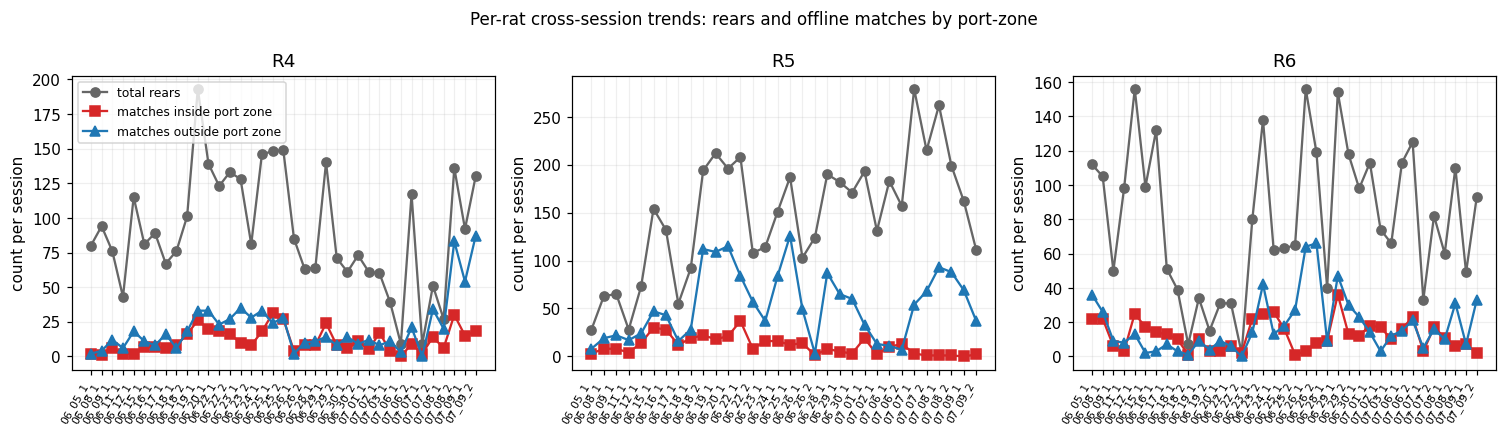

In [196]:
def _per_session_counts(r):
    n_rears = len(r['rears'])
    off_dist = r['offline_match_dist']
    min_port = r['sd']['min_port_distance']
    finite = np.isfinite(off_dist)
    n_in  = int(((off_dist < min_port)  & finite).sum())
    n_out = int(((off_dist >= min_port) & finite).sum())
    return n_rears, n_in, n_out


fig, axes = plt.subplots(1, len(rats_sorted),
                          figsize=(4.6 * len(rats_sorted), 4),
                          squeeze=False, sharey=False)
for col, rat in enumerate(rats_sorted):
    ax = axes[0, col]
    sess = by_rat[rat]
    if not sess:
        ax.axis('off'); continue
    x_labels = [s[5:] for (s, _) in sess]
    rears, inside, outside = [], [], []
    for (s, r) in sess:
        nr, ni, no = _per_session_counts(r)
        rears.append(nr); inside.append(ni); outside.append(no)
    x = np.arange(len(x_labels))
    ax.plot(x, rears,   marker='o', lw=1.5, color='#666',    label='total rears')
    ax.plot(x, inside,  marker='s', lw=1.5, color='#d62728', label='matches inside port zone')
    ax.plot(x, outside, marker='^', lw=1.5, color='#1f77b4', label='matches outside port zone')
    ax.set_xticks(x); ax.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
    ax.set_title(rat)
    ax.set_ylabel('count per session')
    ax.grid(alpha=0.2)
    if col == 0:
        ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Per-rat cross-session trends: rears and offline matches by port-zone',
             fontsize=11)
fig.tight_layout()
plt.show()


### 1.2 First 5 min vs remainder

Same three quantities split by whether each event happened in the first 5 min
of the session (rats often warm up slowly) or after.


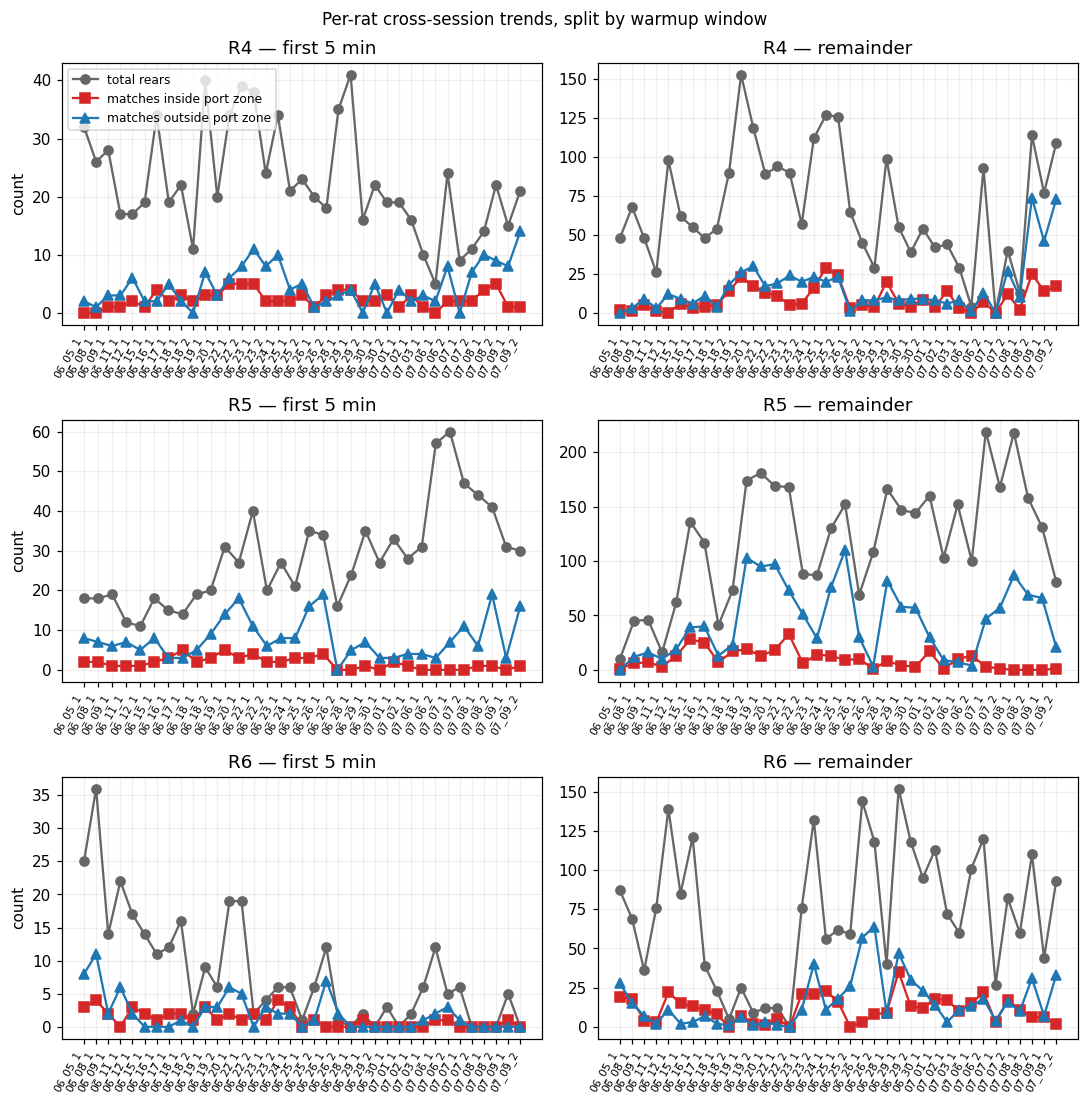

In [197]:
def _per_session_counts_windowed(r, cutoff=WARMUP_FRAMES):
    rear_starts = np.array([rr[0] for rr in r['rears']], dtype=int)
    rear_first  = int((rear_starts <  cutoff).sum())
    rear_rest   = int((rear_starts >= cutoff).sum())
    match_ends  = np.asarray(r['offline_match_cam0'], dtype=int)
    match_dist  = np.asarray(r['offline_match_dist'], dtype=float)
    min_port    = r['sd']['min_port_distance']
    finite      = np.isfinite(match_dist)
    inside      = match_dist < min_port
    outside     = match_dist >= min_port
    first_mask  = (match_ends <  cutoff) & finite
    rest_mask   = (match_ends >= cutoff) & finite
    return ((rear_first, int((first_mask & inside).sum()), int((first_mask & outside).sum())),
            (rear_rest,  int((rest_mask  & inside).sum()), int((rest_mask  & outside).sum())))


fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(10, 3.4 * len(rats_sorted)),
                          squeeze=False, sharey=False)
for row, rat in enumerate(rats_sorted):
    sess = by_rat[rat]
    if not sess:
        for c in range(2):
            axes[row, c].axis('off')
        continue
    x_labels = [s[5:] for (s, _) in sess]
    firsts, rests = [], []
    for (s, r) in sess:
        f, t = _per_session_counts_windowed(r)
        firsts.append(f); rests.append(t)
    first_arr = np.asarray(firsts)
    rest_arr  = np.asarray(rests)
    x = np.arange(len(x_labels))
    for col, (arr, title_suffix) in enumerate(
            [(first_arr, 'first 5 min'), (rest_arr, 'remainder')]):
        ax = axes[row, col]
        ax.plot(x, arr[:, 0], marker='o', lw=1.5, color='#666',    label='total rears')
        ax.plot(x, arr[:, 1], marker='s', lw=1.5, color='#d62728', label='matches inside port zone')
        ax.plot(x, arr[:, 2], marker='^', lw=1.5, color='#1f77b4', label='matches outside port zone')
        ax.set_xticks(x); ax.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
        ax.set_title(f'{rat} — {title_suffix}')
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel('count')
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc='upper left')
fig.suptitle('Per-rat cross-session trends, split by warmup window',
             fontsize=11)
fig.tight_layout()
plt.show()


### 1.3 Dropped frames per session

`cam0` advances faster than SLEAP can process; the gap is the dropped-frame
rate (computed as `1 - n_processed / (max_cam0 + 1)`).


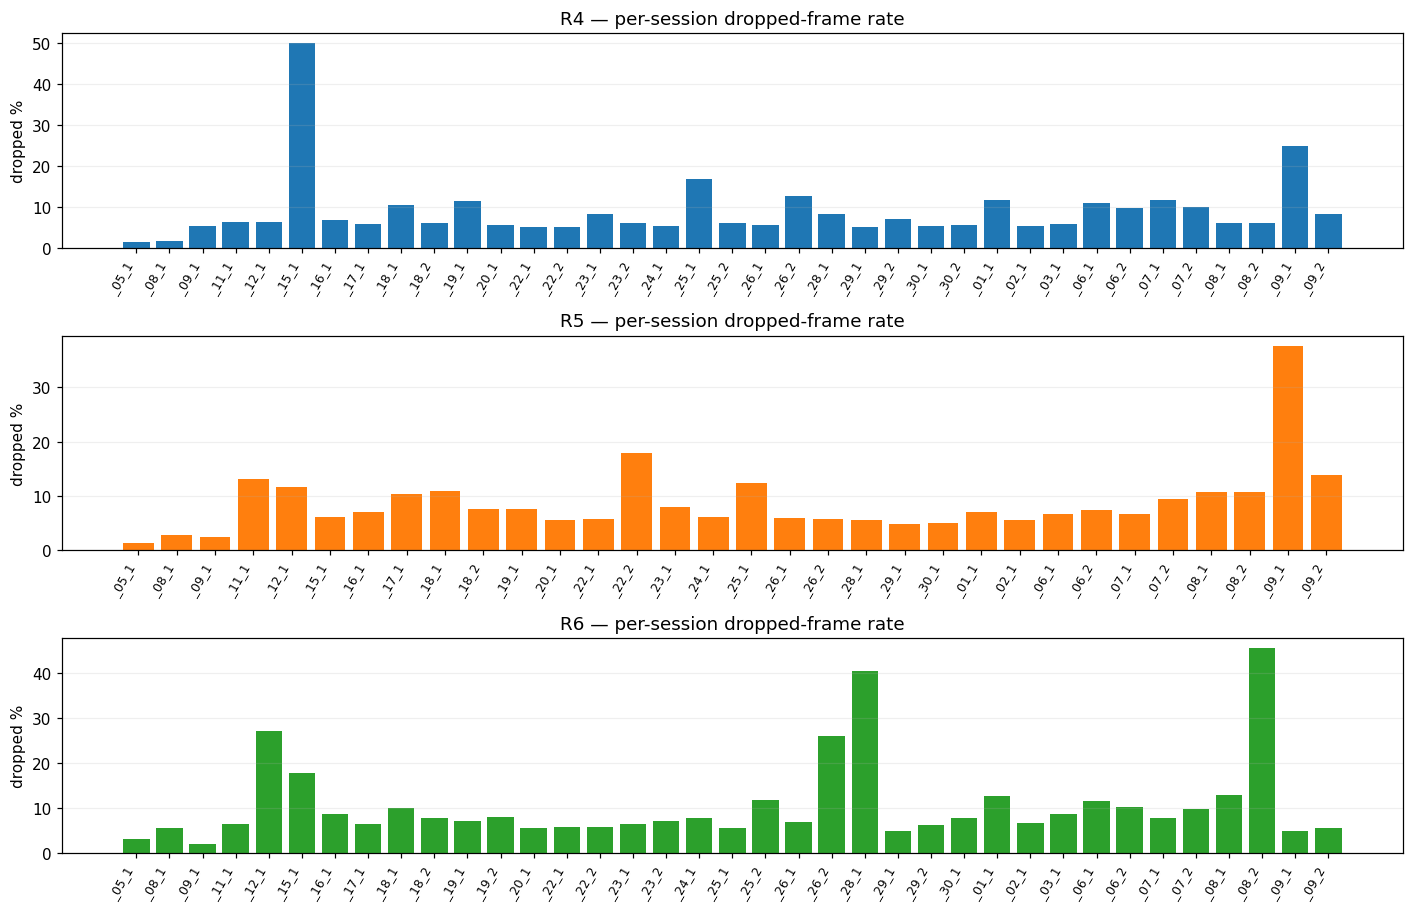

In [198]:
# One subplot per rat (was: all rats interleaved on a single axis).
_rats_present = [rt for rt in RATS if any(k[0] == rt for k in RESULTS)]
_n_rat = len(_rats_present)
fig, axes = plt.subplots(_n_rat, 1, figsize=(max(8, 0.35 * max(
    (sum(1 for k in RESULTS if k[0] == rt) for rt in _rats_present), default=1)),
    2.8 * _n_rat), squeeze=False)
axes = axes[:, 0]

for _axi, _rat in enumerate(_rats_present):
    ax = axes[_axi]
    _sk = sorted(s for (rt, s) in RESULTS if rt == _rat)
    labels = [s[-5:] for s in _sk]
    rates  = [RESULTS[(_rat, s)]['drop_rate'] * 100 for s in _sk]
    x = np.arange(len(labels))
    ax.bar(x, rates, color=RAT_COLOR.get(_rat, '#888'))
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_ylabel('dropped %')
    ax.set_title(f'{_rat} — per-session dropped-frame rate')
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); plt.show()


### 1.4 Per-session rear counts

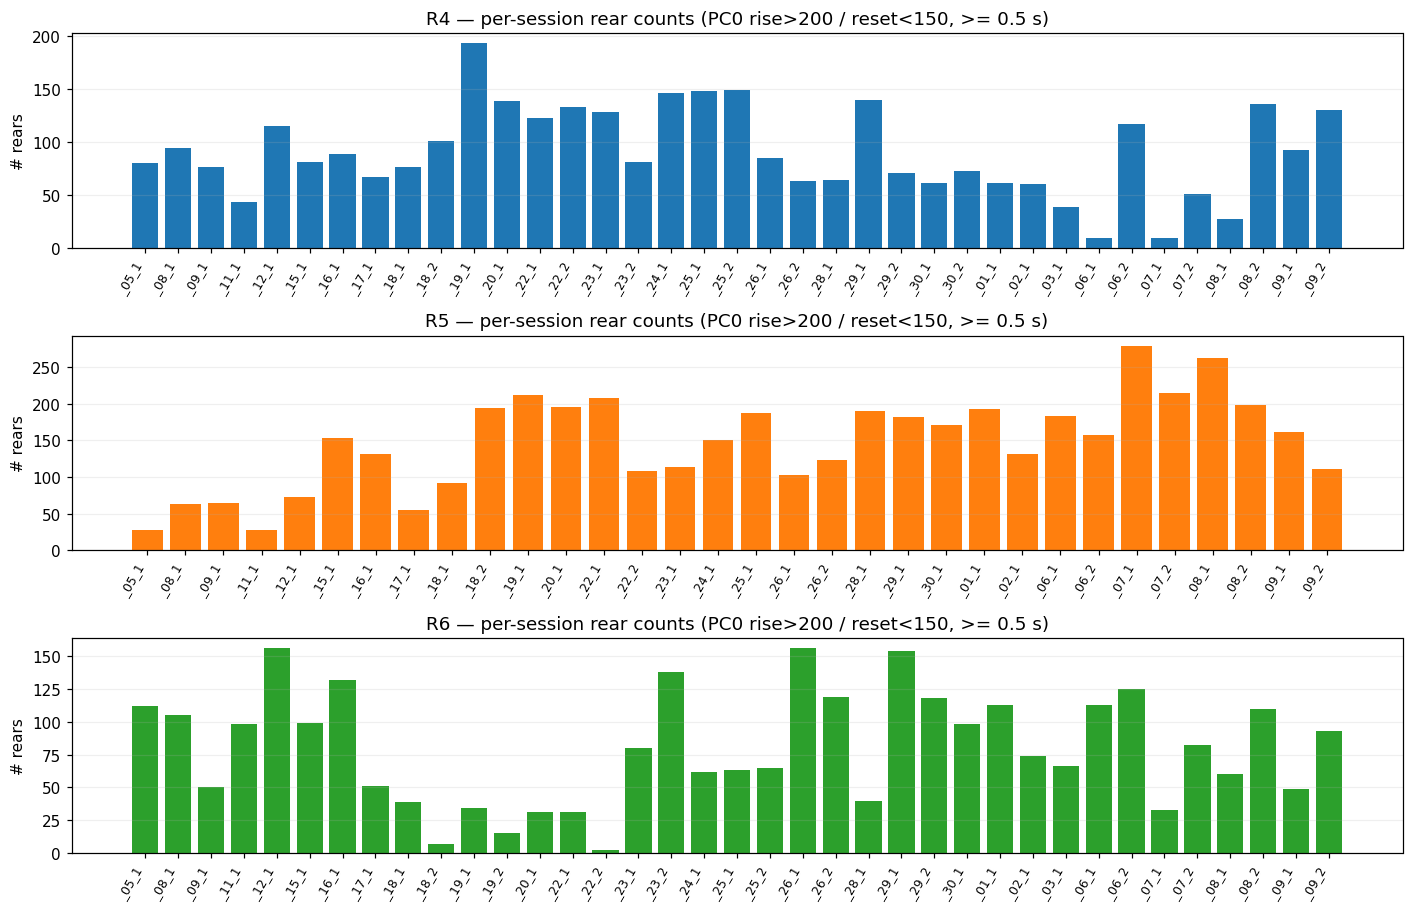

In [199]:
# One subplot per rat (was: all rats interleaved on a single axis).
_rats_present = [rt for rt in RATS if any(k[0] == rt for k in RESULTS)]
_n_rat = len(_rats_present)
fig, axes = plt.subplots(_n_rat, 1, figsize=(max(8, 0.35 * max(
    (sum(1 for k in RESULTS if k[0] == rt) for rt in _rats_present), default=1)),
    2.8 * _n_rat), squeeze=False)
axes = axes[:, 0]

for _axi, _rat in enumerate(_rats_present):
    ax = axes[_axi]
    _sk = sorted(s for (rt, s) in RESULTS if rt == _rat)
    labels = [s[-5:] for s in _sk]
    counts = [len(RESULTS[(_rat, s)]['rears']) for s in _sk]
    x = np.arange(len(labels))
    ax.bar(x, counts, color=RAT_COLOR.get(_rat, '#888'))
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_ylabel('# rears')
    ax.set_title(f'{_rat} — per-session rear counts (PC0 rise>200 / reset<150, >= 0.5 s)')
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); plt.show()


### 1.5 Per-session rear duration (mean ± std)

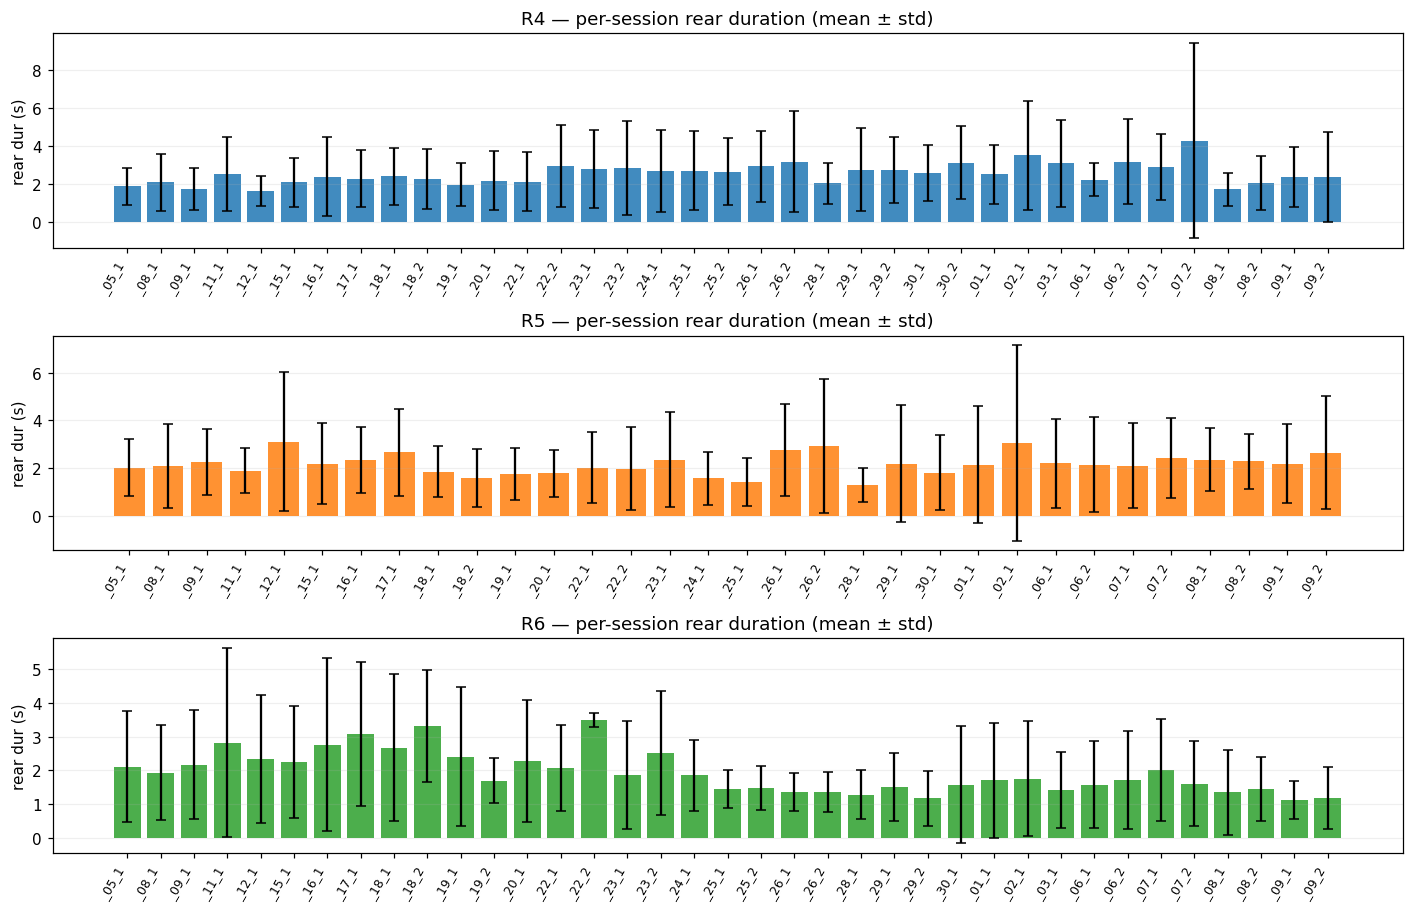

In [200]:
# One subplot per rat (was: all rats interleaved on a single axis).
_rats_present = [rt for rt in RATS if any(k[0] == rt for k in RESULTS)]
_n_rat = len(_rats_present)
fig, axes = plt.subplots(_n_rat, 1, figsize=(max(8, 0.35 * max(
    (sum(1 for k in RESULTS if k[0] == rt) for rt in _rats_present), default=1)),
    2.8 * _n_rat), squeeze=False)
axes = axes[:, 0]

for _axi, _rat in enumerate(_rats_present):
    ax = axes[_axi]
    _sk = sorted(s for (rt, s) in RESULTS if rt == _rat)
    labels, means, stds = [], [], []
    for s in _sk:
        rears = RESULTS[(_rat, s)]['rears']
        # duration = full reared posture width (start -> drop below reset)
        durs_s = np.array([(e - st) / SLEAP_HZ for (st, e, _) in rears])
        labels.append(s[-5:])
        means.append(float(durs_s.mean()) if len(durs_s) else 0.0)
        stds.append(float(durs_s.std())   if len(durs_s) else 0.0)
    x = np.arange(len(labels))
    ax.bar(x, means, yerr=stds, color=RAT_COLOR.get(_rat, '#888'), capsize=3, alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_ylabel('rear dur (s)')
    ax.set_title(f'{_rat} — per-session rear duration (mean ± std)')
    ax.grid(axis='y', alpha=0.2)
fig.tight_layout(); plt.show()


### 1.6 % of rears that produced an offline match

For each session and group (rears starting inside the port-exclusion zone vs
outside), the fraction of rears whose interval overlaps an offline match's
30-frame template window. Each rat gets two panels: first 5 min vs the rest.


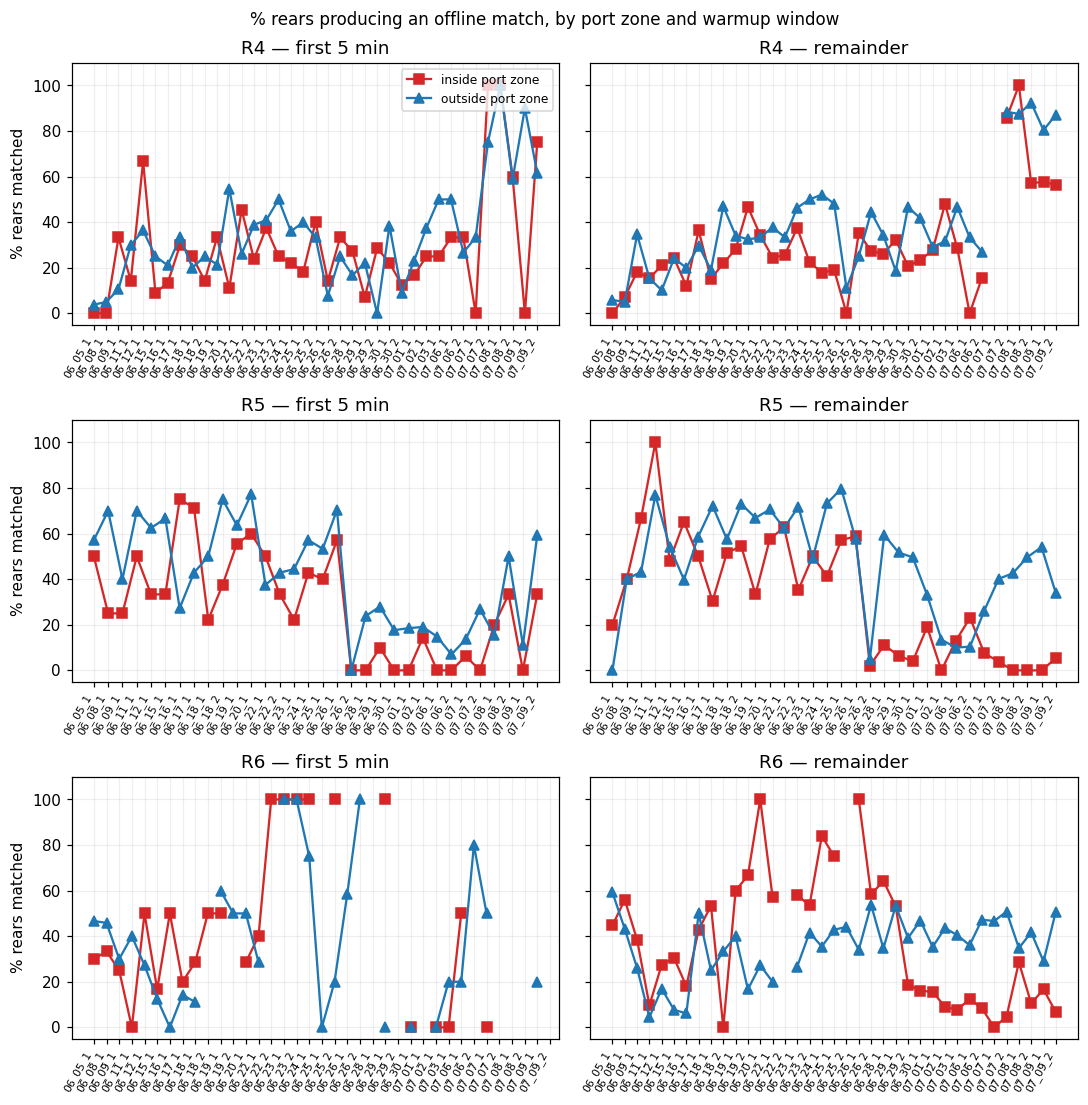

In [201]:
def _pct_rears_matched(r, mask_fn):
    rears = r['rears']
    if not rears:
        return np.nan, np.nan, 0, 0
    starts   = np.array([rr[0] for rr in rears])
    port_dist = r['port_dist']
    min_port  = r['sd']['min_port_distance']
    d_start  = port_dist[np.clip(starts, 0, len(port_dist) - 1)]
    inside_m  = (d_start <  min_port) & np.isfinite(d_start)
    outside_m = (d_start >= min_port) & np.isfinite(d_start)
    keep = mask_fn(starts)
    hit  = _attributed_rears_mask(rears, r['offline_match_cam0'])
    def _pct(mask):
        n = int(mask.sum())
        return ((hit & mask).sum() / n * 100) if n else np.nan, n
    pct_in,  n_in  = _pct(inside_m  & keep)
    pct_out, n_out = _pct(outside_m & keep)
    return pct_in, pct_out, n_in, n_out


fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(10, 3.4 * len(rats_sorted)),
                          squeeze=False, sharey=True)
for row, rat in enumerate(rats_sorted):
    sess = by_rat[rat]
    if not sess:
        for c in range(2):
            axes[row, c].axis('off')
        continue
    x_labels = [s[5:] for (s, _) in sess]
    x = np.arange(len(x_labels))
    for col, (mask_fn, title_suffix) in enumerate([
            (lambda starts: starts <  WARMUP_FRAMES, 'first 5 min'),
            (lambda starts: starts >= WARMUP_FRAMES, 'remainder')]):
        pct_in_arr, pct_out_arr = [], []
        n_in_arr,   n_out_arr   = [], []
        for (s, r) in sess:
            pi, po, ni, no = _pct_rears_matched(r, mask_fn)
            pct_in_arr.append(pi); pct_out_arr.append(po)
            n_in_arr.append(ni);   n_out_arr.append(no)
        ax = axes[row, col]
        ax.plot(x, pct_in_arr,  marker='s', lw=1.5, color='#d62728',
                label='inside port zone')
        ax.plot(x, pct_out_arr, marker='^', lw=1.5, color='#1f77b4',
                label='outside port zone')
        ax.set_xticks(x); ax.set_xticklabels(x_labels, rotation=60, fontsize=7, ha='right')
        ax.set_ylim(-5, 110)
        ax.set_title(f'{rat} — {title_suffix}')
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel('% rears matched')
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc='upper right')
fig.suptitle('% rears producing an offline match, by port zone and warmup window',
             fontsize=11)
fig.tight_layout()
plt.show()


### 1.7 Attempts, success rate, rear-shape, and training-state trends

Cross-session view of the analyses introduced in `single_session.ipynb`:

- **Attempts** — a rear followed by a lick bout (licks ≥ 2 s apart) within 10 s.
  Each lick bout attaches to the most-recent rear (never re-used).
- **Success** — attempt whose rear overlaps an offline template match (same
  overlap rule as 1.6).
- **train_state** — read from `sleap/campy_config.yaml → behavior_params.train_state`.
  0 = no tone, no water on match. 1 = tone on match. 2 = tone + water on match.
  Every plot below overlays the train_state:
  - Colored dot above each session's bar/row.
  - Vertical dashed line where the train_state changes (per rat).

Every RESULTS entry from section 1 is extended in place with `lick_frames`,
`lick_bout_frames`, `attempt_rear_idx`, `attempt_lick_frame`, `attempt_matched`,
`attempt_inside_port`, `rear_matched`, `rear_inside_port`, `rear_align_end`,
`rear_align_mse`, `train_state`.


In [202]:
# --- section 1.8 helpers ---
import yaml
import scipy.io as _sio

LICK_BOUT_GAP_S   = 2.0
ATTEMPT_WINDOW_S  = 10.0
ALIGN_BUFFER_S    = 0.75
PROG_BIN_S        = 300.0     # 5-min bins for progression / heatmaps

LICK_GAP_FR   = int(round(LICK_BOUT_GAP_S  * SLEAP_HZ))
ATT_WIN_FR    = int(round(ATTEMPT_WINDOW_S * SLEAP_HZ))
ALIGN_BUF_FR  = int(round(ALIGN_BUFFER_S   * SLEAP_HZ))
PROG_BIN_FR   = int(round(PROG_BIN_S       * SLEAP_HZ))

# train_state palette. Missing state -> grey with question-mark marker.
TRAIN_STATE_COLOR = {0: '#888', 1: '#1f77b4', 2: '#2ca02c'}
TRAIN_STATE_LABEL = {0: 'state 0 (no tone/water)',
                     1: 'state 1 (tone only)',
                     2: 'state 2 (tone + water)'}


def _load_train_state(rat, session):
    """train_state from the cached campy_config.yaml value. NaN on miss."""
    _c = sc.get_raw_session(rat, session, want_dual=False)
    return _c['train_state'] if _c is not None else np.nan


def _lick_frames_from_aligned(rat, session, n_frames):
    """Lick onset frames from the cached lick_idx_sleap_cams vector (onset where
    the nearest-lick index increments). Raw vector via the local session cache."""
    _c = sc.get_raw_session(rat, session, want_dual=False)
    if _c is None:
        return np.array([], dtype=int)
    lidx = np.asarray(_c['lick_idx_sleap_cams'], dtype=int).ravel()[:n_frames]
    if not len(lidx):
        return np.array([], dtype=int)
    diff = np.diff(lidx, prepend=lidx[:1])
    return np.where(diff > 0)[0].astype(int)


def _lick_bouts(lick_frames, gap_fr=LICK_GAP_FR):
    if not len(lick_frames):
        return lick_frames
    gaps = np.diff(lick_frames, prepend=lick_frames[:1] - gap_fr - 1)
    return lick_frames[gaps >= gap_fr]


def _attempts(rear_end, lick_bout_frames, att_win_fr=ATT_WIN_FR):
    """Return (attempt_rear_idx, attempt_lick_frame). Each lick bout attaches
    to the most-recent (largest-end) unclaimed rear ending in [lf-att_win_fr, lf]."""
    n_rears = len(rear_end)
    attempt_ri, attempt_lf = [], []
    used = np.zeros(n_rears, dtype=bool)
    for lf in lick_bout_frames:
        cand = (rear_end >= lf - att_win_fr) & (rear_end <= lf) & ~used
        if cand.any():
            idx = np.where(cand)[0]
            j = idx[int(np.argmax(rear_end[idx]))]
            used[j] = True
            attempt_ri.append(j)
            attempt_lf.append(int(lf))
    return np.asarray(attempt_ri, dtype=int), np.asarray(attempt_lf, dtype=int)


def _rear_matched(rear_start, rear_end, match_cam0, template_len=TEMPLATE_LEN):
    """Return (hit, match_end_frame). hit[k] True if any offline match's 30-frame
    window overlaps rear k; match_end_frame[k] is that match's end frame (== the
    trigger frame the online rig evaluated the port gate on), or -1 if unmatched."""
    n_rears = len(rear_start)
    hit = np.zeros(n_rears, dtype=bool)
    match_end_frame = np.full(n_rears, -1, dtype=int)
    m_end = np.asarray(match_cam0, dtype=int)
    if not n_rears or not len(m_end):
        return hit, match_end_frame
    m_start = m_end - (template_len - 1)
    for k in range(n_rears):
        ov = np.where((m_start <= rear_end[k]) & (m_end >= rear_start[k]))[0]
        if ov.size:
            hit[k] = True
            match_end_frame[k] = int(m_end[ov[0]])
    return hit, match_end_frame


def _best_align_end(rs, re, pcs, template, buf=ALIGN_BUF_FR):
    """End-frame in [rs, re+buf] whose 30-frame window minimizes MSE to template."""
    L = template.shape[0]
    e_min = max(rs, L - 1)
    e_max = min(re + buf, len(pcs) - 1)
    if e_max < e_min:
        return -1, np.nan
    ends = np.arange(e_min, e_max + 1)
    starts = ends - (L - 1)
    idx = starts[:, None] + np.arange(L)[None, :]
    win = pcs[idx, :template.shape[1]]
    mse = ((win - template[None]) ** 2).mean(axis=(1, 2))
    k = int(np.argmin(mse))
    return int(ends[k]), float(mse[k])


# ---- Populate RESULTS with the new per-session fields ----
for (rat, s), r in RESULTS.items():
    sd = r['sd']
    n_frames = len(sd['triang_3d'])
    r['train_state'] = _load_train_state(rat, s)

    # licks + bouts + attempts
    lf = _lick_frames_from_aligned(rat, s, n_frames)
    lb = _lick_bouts(lf)
    r['lick_frames']       = lf
    r['lick_bout_frames']  = lb

    rears = r['rears']
    rear_start = np.array([rr[0] for rr in rears], dtype=int)
    rear_end   = np.array([rr[1] for rr in rears], dtype=int)
    a_ri, a_lf = _attempts(rear_end, lb)
    r['attempt_rear_idx']    = a_ri
    r['attempt_lick_frame']  = a_lf

    # per-rear labels
    r['rear_matched'], _rear_match_end = _rear_matched(
        rear_start, rear_end, r['offline_match_cam0'])
    if len(rears):
        port_dist = r['port_dist']
        # Gate the port-distance test at the frame the online rig evaluated it:
        # the MATCH-END (trigger) frame for matched rears, else the rear-END frame
        # (top of the reared posture -- closest analog where a match would complete).
        # NOT the rear-START frame: the animal moves toward the port while rearing,
        # so rear-start would mislabel rears that start far but complete near the port.
        gate_frame = np.where(_rear_match_end >= 0, _rear_match_end, rear_end)
        gate_frame = np.clip(gate_frame, 0, len(port_dist) - 1)
        d = port_dist[gate_frame]
        min_port = sd['min_port_distance']
        r['rear_inside_port'] = (d < min_port) & np.isfinite(d)
        r['rear_gate_frame']  = gate_frame
    else:
        r['rear_inside_port'] = np.zeros(0, dtype=bool)
        r['rear_gate_frame']  = np.zeros(0, dtype=int)

    # attempt-derived labels
    if len(a_ri):
        r['attempt_matched']     = r['rear_matched'][a_ri]
        r['attempt_inside_port'] = r['rear_inside_port'][a_ri]
    else:
        r['attempt_matched']     = np.zeros(0, dtype=bool)
        r['attempt_inside_port'] = np.zeros(0, dtype=bool)

    # rear-shape max-alignment window (needs template + bounds + PCs)
    tmpl = sd['template']
    pcs_to_use = np.asarray(tmpl['pcs_to_use']).ravel().astype(int)
    pc_template = tmpl['template'][:, :N_COMPONENTS]
    pcs_used = r['pcs_full'][:, pcs_to_use[:N_COMPONENTS]]
    r['pcs_used'] = pcs_used     # cached for 1.8f
    r['pc_template'] = pc_template
    r['bounds_to_use'] = tmpl['bounds_to_use'][:, :N_COMPONENTS]
    r['rear_start'] = rear_start
    r['rear_end']   = rear_end
    if len(rears):
        ends = np.full(len(rears), -1, dtype=int)
        mses = np.full(len(rears), np.nan)
        for k in range(len(rears)):
            ends[k], mses[k] = _best_align_end(rear_start[k], rear_end[k], pcs_used, pc_template)
        r['rear_align_end'] = ends
        r['rear_align_mse'] = mses
    else:
        r['rear_align_end'] = np.zeros(0, dtype=int)
        r['rear_align_mse'] = np.zeros(0)

# Quick summary
print(f'{"rat":<3} {"session":<14} {"ts":>3}  {"rears":>6} {"licks":>6} {"bouts":>6} {"attempts":>9} {"matched":>8}')
for (rat, s), r in sorted(RESULTS.items()):
    ts = r['train_state']
    ts_s = f'{int(ts)}' if np.isfinite(ts) else '?'
    print(f'{rat:<3} {s:<14} {ts_s:>3}  {len(r["rears"]):>6d} '
          f'{len(r["lick_frames"]):>6d} {len(r["lick_bout_frames"]):>6d} '
          f'{len(r["attempt_rear_idx"]):>9d} {int(r["attempt_matched"].sum()):>8d}')


rat session         ts   rears  licks  bouts  attempts  matched
R4  2026_06_05_1     1      80     65     53        27        1
R4  2026_06_08_1     1      94     45     34        15        0
R4  2026_06_09_1     2      76     39     35        23        4
R4  2026_06_11_1     2      43     54     39        11        1
R4  2026_06_12_1     2     115    104     79        19        4
R4  2026_06_15_1     2      81    121     92        29        6
R4  2026_06_16_1     2      89     80     63        24        4
R4  2026_06_17_1     1      67    146     92        29       10
R4  2026_06_18_1     1      76    329    190        47        7
R4  2026_06_18_2     1     101    484    289        84       30
R4  2026_06_19_1     1     193      0      0         0        0
R4  2026_06_20_1     1     139    162    151        88       36
R4  2026_06_22_1     1     123    130    118        59       24
R4  2026_06_22_2     0     133    123    113        53       18
R4  2026_06_23_1     0     128    116   

In [203]:
# --- train_state overlay helper ---
def _train_state_dots(ax, states, xs, y_frac=1.02):
    """Draw a colored dot per session above the bar at (xs, y_top*y_frac)."""
    y_top = ax.get_ylim()[1]
    for x, ts in zip(xs, states):
        if not np.isfinite(ts):
            c = 'k'; label = '?'
            ax.scatter(x, y_top * y_frac, marker='?', color=c, s=40, zorder=5)
        else:
            c = TRAIN_STATE_COLOR.get(int(ts), '#000')
            ax.scatter(x, y_top * y_frac, marker='o', color=c, edgecolor='k',
                        s=40, zorder=5)


def _train_state_transitions(sessions_states):
    """Given ordered [(x_pos, train_state)], return list of x positions
    just before each transition (draw a dashed line between session i-1 and i)."""
    xs = []
    prev = None
    for x, ts in sessions_states:
        if prev is None:
            prev = (x, ts); continue
        # transition detected if both are finite and differ
        if np.isfinite(prev[1]) and np.isfinite(ts) and int(prev[1]) != int(ts):
            xs.append((prev[0] + x) / 2.0)
        prev = (x, ts)
    return xs


def _train_state_legend(ax, loc='upper right', fontsize=7):
    from matplotlib.lines import Line2D
    handles = [Line2D([0], [0], marker='o', color='w', label=lbl,
                       markerfacecolor=c, markeredgecolor='k', markersize=6)
                for state, c in TRAIN_STATE_COLOR.items()
                for lbl in [TRAIN_STATE_LABEL[state]]]
    ax.legend(handles=handles, loc=loc, fontsize=fontsize, framealpha=0.85)


#### 1.8a Session totals — rears, lick bouts, attempts

One panel per rat. Three bars per session (rears, lick bouts, attempts). Colored
dot above each session marks the train_state; vertical dashed lines mark
train_state transitions.


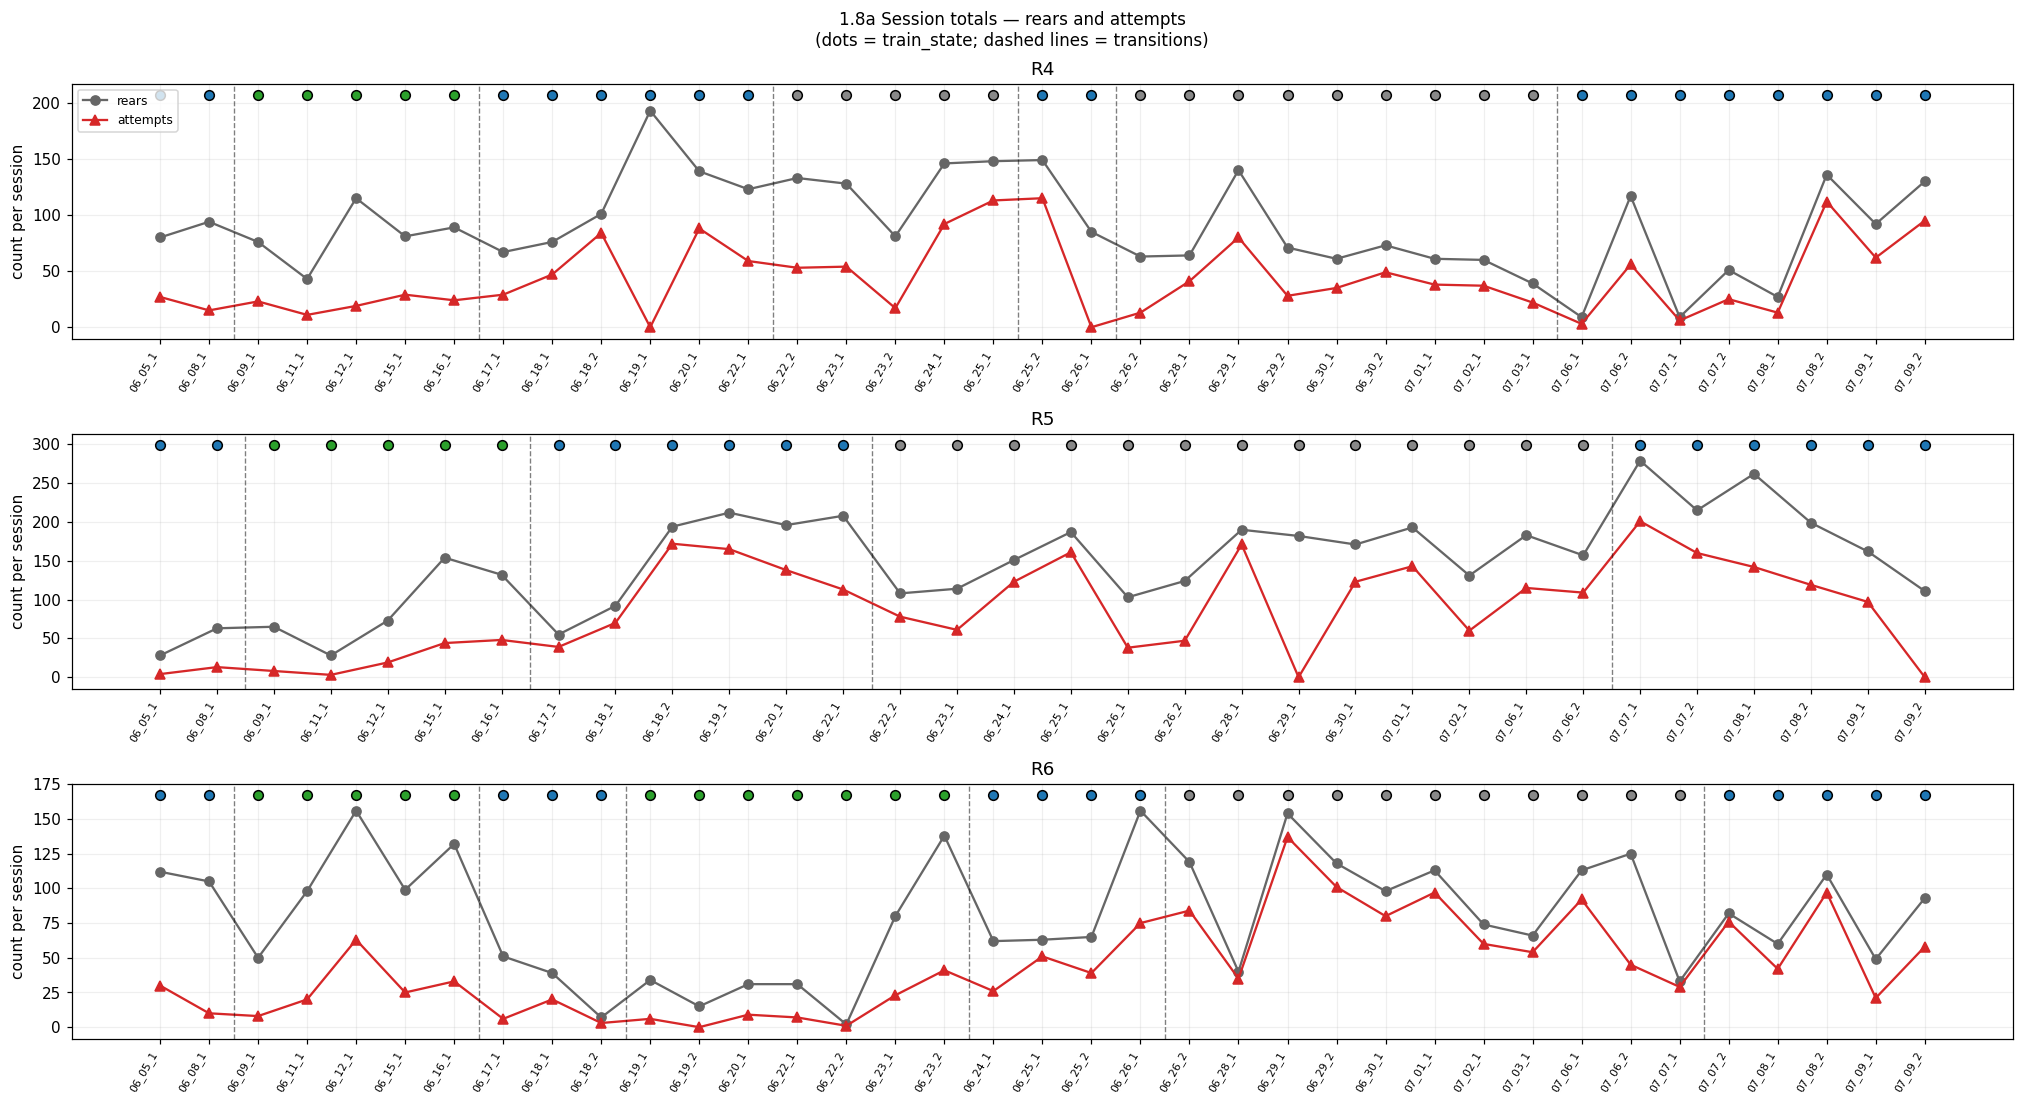

In [204]:
fig, axes = plt.subplots(len(rats_sorted), 1,
                          figsize=(max(9, 0.5 * max(len(by_rat[r]) for r in rats_sorted)),
                                   3.4 * len(rats_sorted)),
                          squeeze=False)
for row, rat in enumerate(rats_sorted):
    ax = axes[row, 0]
    sess = by_rat[rat]
    x = np.arange(len(sess))
    rears     = [len(r['rears']) for _, r in sess]
    attempts  = [len(r['attempt_rear_idx']) for _, r in sess]
    states    = [r['train_state'] for _, r in sess]

    ax.plot(x, rears,    marker='o', lw=1.5, color='#666',    label='rears')
    ax.plot(x, attempts, marker='^', lw=1.5, color='#d62728', label='attempts')
    ax.set_xticks(x)
    ax.set_xticklabels([s[5:] for s, _ in sess], rotation=60, fontsize=7, ha='right')
    ax.set_ylabel('count per session')
    ax.set_title(f'{rat}')
    ax.grid(alpha=0.2)
    for xt in _train_state_transitions(list(zip(x, states))):
        ax.axvline(xt, color='k', ls='--', lw=0.9, alpha=0.5)
    _train_state_dots(ax, states, x)
    if row == 0:
        ax.legend(fontsize=8, loc='upper left')

fig.suptitle('1.8a Session totals — rears and attempts\n'
             '(dots = train_state; dashed lines = transitions)', fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8a-2 Attempts as a fraction of rears

For each session, the fraction of rears that were followed by a lick bout within
10 s (i.e. attempts / rears). Independent of match rate — a high value means
the animal reliably approaches the port after rearing, a low value means she
rears without pursuing the reward.


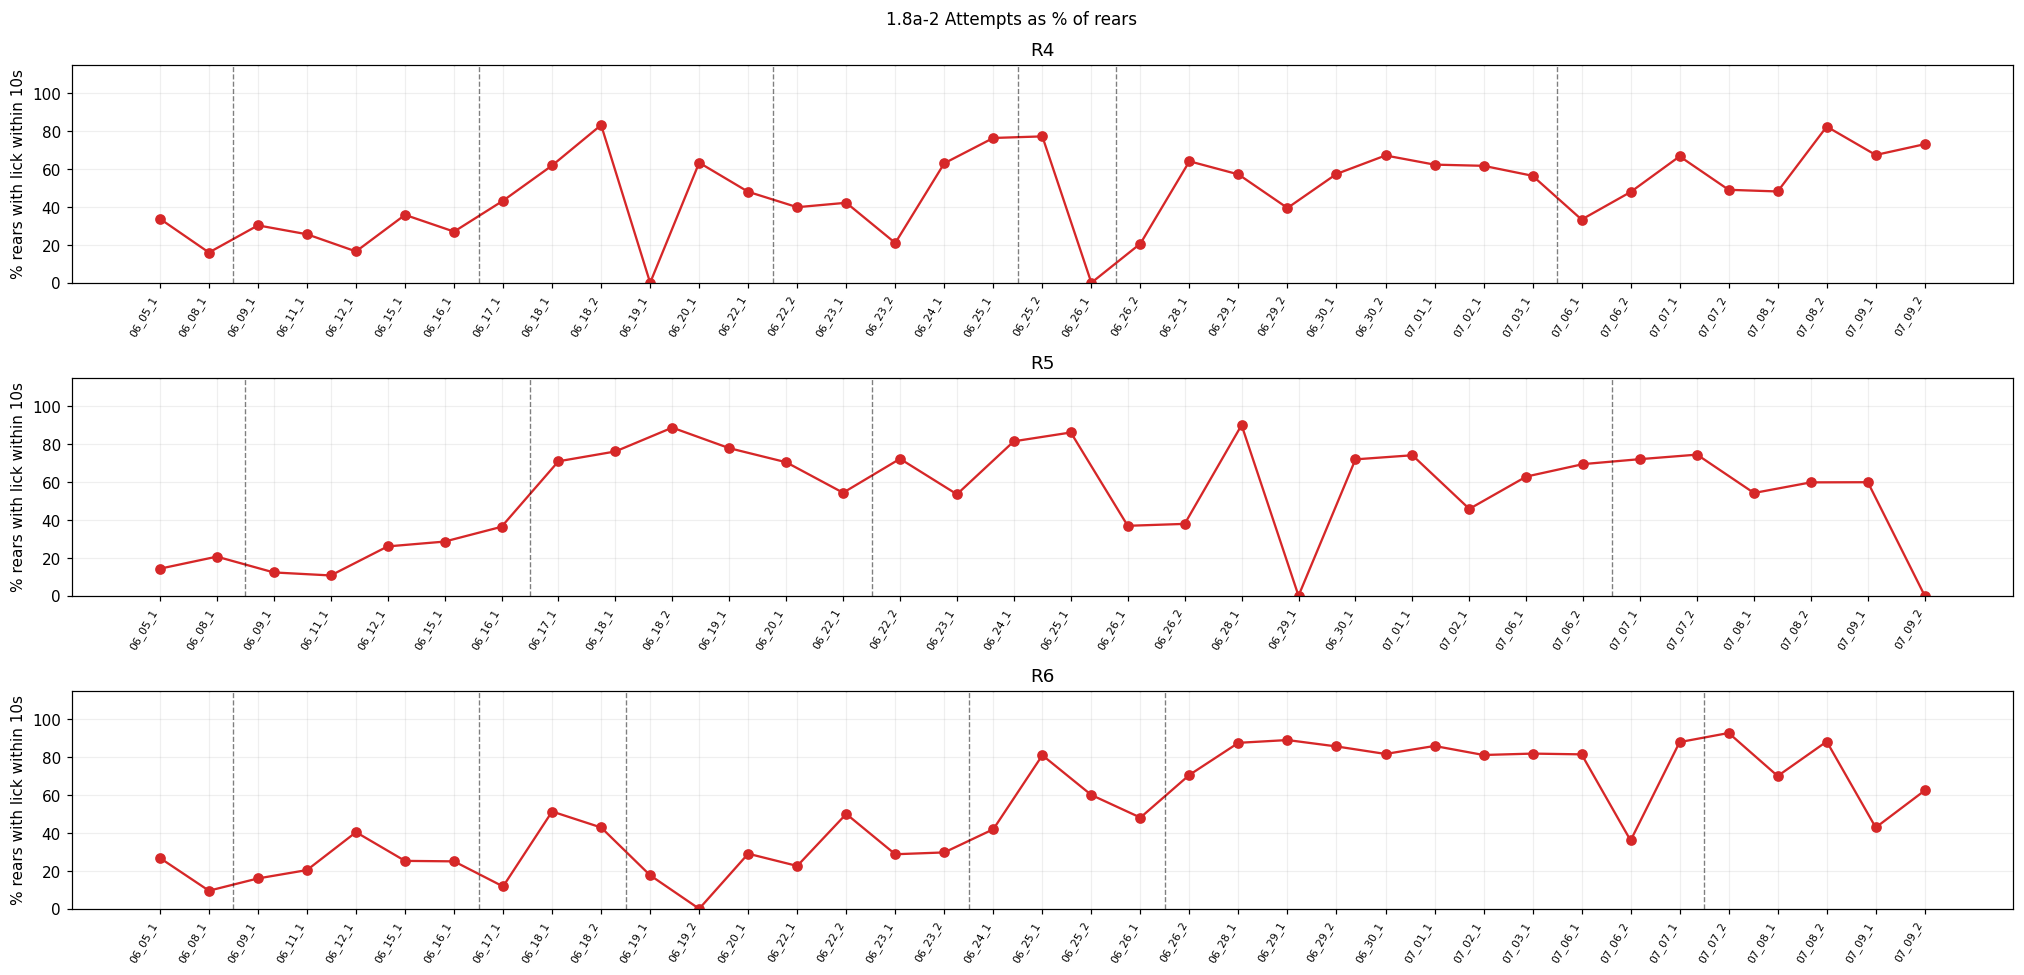

In [205]:
fig, axes = plt.subplots(len(rats_sorted), 1,
                          figsize=(max(9, 0.5 * max(len(by_rat[r]) for r in rats_sorted)),
                                   3.0 * len(rats_sorted)),
                          squeeze=False, sharey=True)
for row, rat in enumerate(rats_sorted):
    ax = axes[row, 0]
    sess = by_rat[rat]
    x = np.arange(len(sess))
    pct = []
    states = []
    for _, r in sess:
        n_r = len(r['rears'])
        n_a = len(r['attempt_rear_idx'])
        pct.append(100.0 * n_a / n_r if n_r else np.nan)
        states.append(r['train_state'])
    ax.plot(x, pct, marker='o', lw=1.5, color='#d62728',
             label='attempts / rears')
    ax.set_xticks(x)
    ax.set_xticklabels([s[5:] for s, _ in sess], rotation=60, fontsize=7, ha='right')
    ax.set_ylabel('% rears with lick within 10s')
    ax.set_ylim(0, 115)
    ax.set_title(f'{rat}')
    ax.grid(alpha=0.2)
    for xt in _train_state_transitions(list(zip(x, states))):
        ax.axvline(xt, color='k', ls='--', lw=0.9, alpha=0.5)
    _train_state_dots(ax, states, x)

fig.suptitle('1.8a-2 Attempts as % of rears', fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8b % attempts matched — session-wide, split by port zone

For each session, the fraction of attempts whose rear overlapped a template
match, split by whether the rear started inside the port-exclusion zone or
outside. n above each bar = number of attempts in that group.


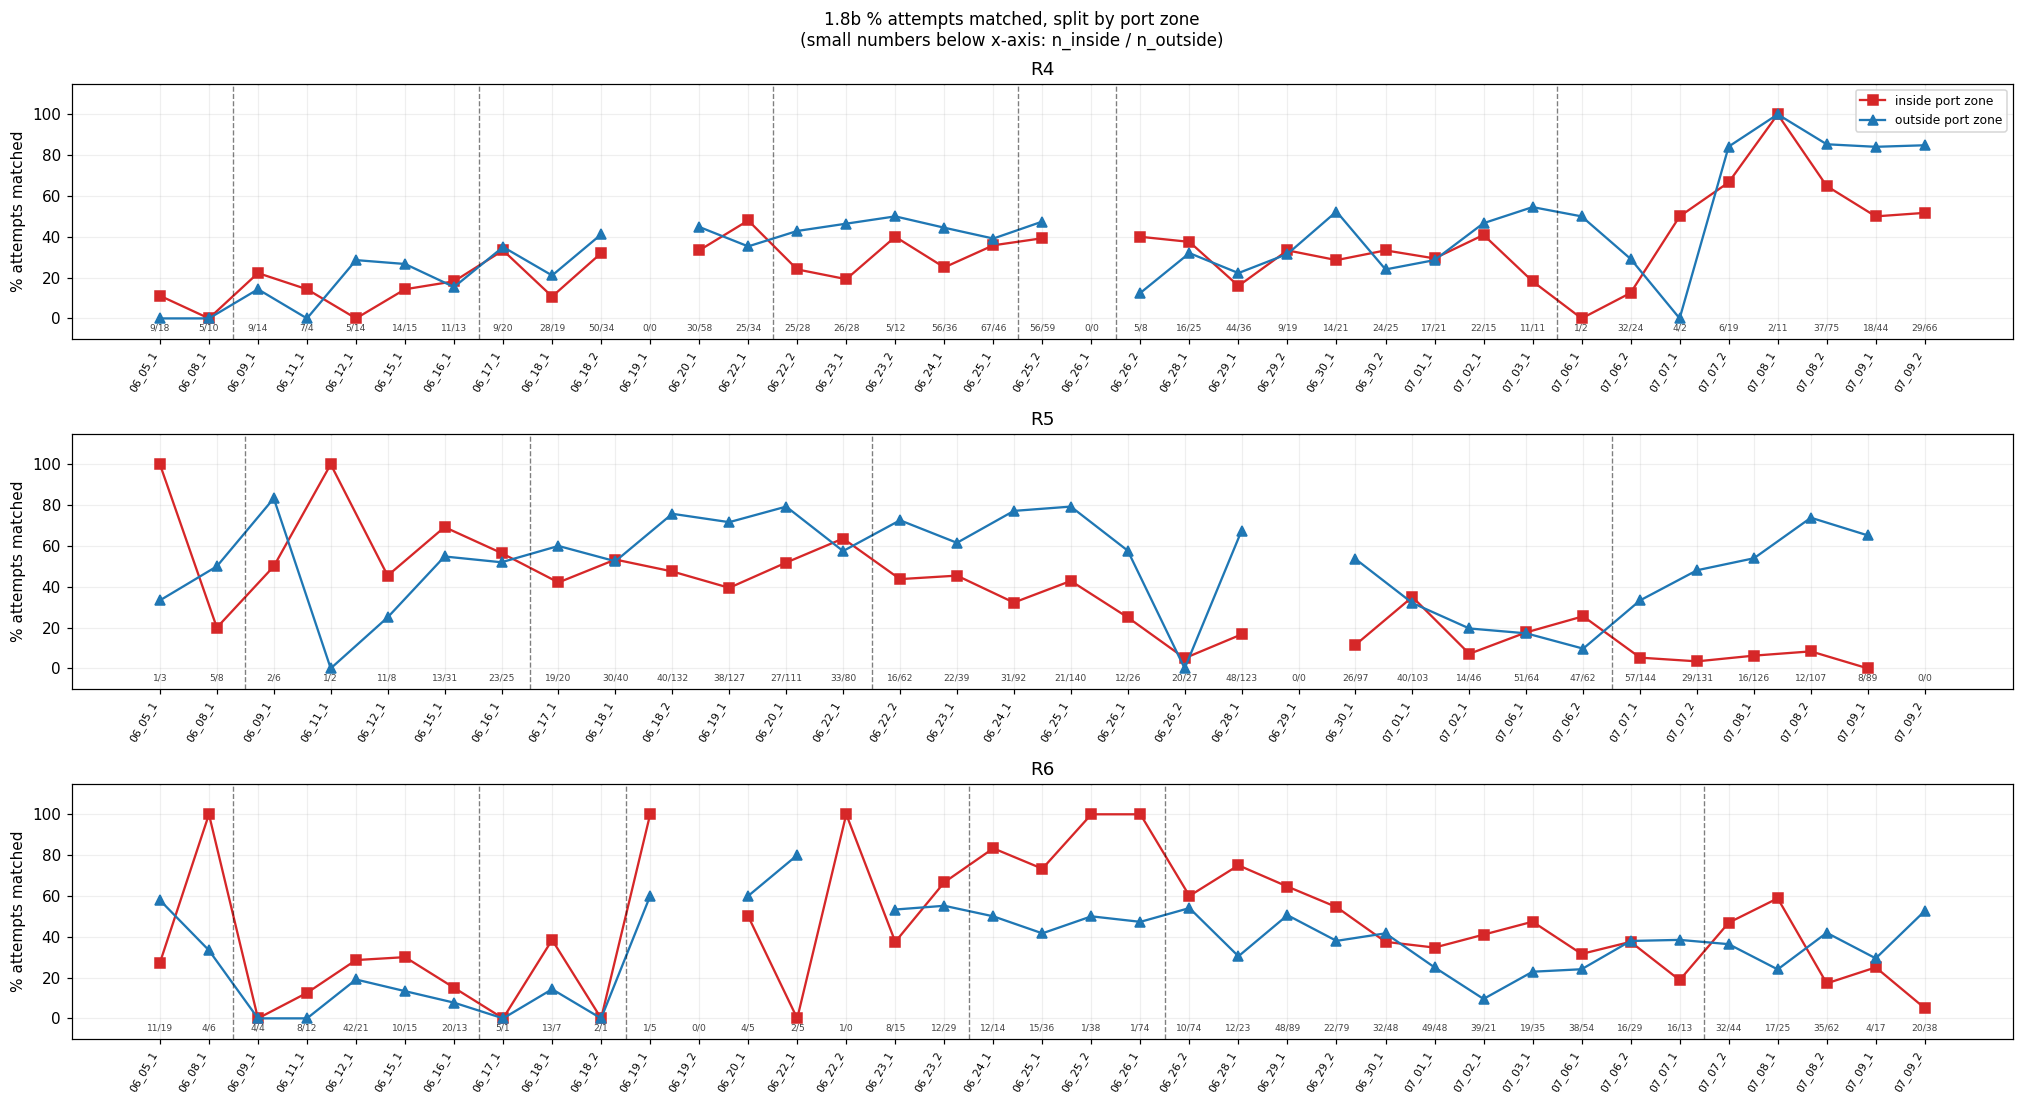

In [206]:
fig, axes = plt.subplots(len(rats_sorted), 1,
                          figsize=(max(9, 0.5 * max(len(by_rat[r]) for r in rats_sorted)),
                                   3.4 * len(rats_sorted)),
                          squeeze=False, sharey=True)
for row, rat in enumerate(rats_sorted):
    ax = axes[row, 0]
    sess = by_rat[rat]
    x = np.arange(len(sess))
    pct_in, pct_out, n_in, n_out, states = [], [], [], [], []
    for _, r in sess:
        m = r['attempt_matched']; ip = r['attempt_inside_port']
        n_i = int(ip.sum()); n_o = int((~ip).sum())
        pct_in.append(100.0 * (m & ip).sum() / n_i if n_i else np.nan)
        pct_out.append(100.0 * (m & ~ip).sum() / n_o if n_o else np.nan)
        n_in.append(n_i); n_out.append(n_o)
        states.append(r['train_state'])
    ax.plot(x, pct_in,  marker='s', lw=1.5, color='#d62728',
             label='inside port zone')
    ax.plot(x, pct_out, marker='^', lw=1.5, color='#1f77b4',
             label='outside port zone')
    # small n annotation below each x-tick
    for xi in range(len(x)):
        ax.text(x[xi], -6, f'{n_in[xi]}/{n_out[xi]}',
                 ha='center', fontsize=6, color='#444')
    ax.set_xticks(x)
    ax.set_xticklabels([s[5:] for s, _ in sess], rotation=60, fontsize=7, ha='right')
    ax.set_ylabel('% attempts matched')
    ax.set_ylim(-10, 115)
    ax.set_title(f'{rat}')
    ax.grid(alpha=0.2)
    for xt in _train_state_transitions(list(zip(x, states))):
        ax.axvline(xt, color='k', ls='--', lw=0.9, alpha=0.5)
    _train_state_dots(ax, states, x)
    if row == 0:
        ax.legend(fontsize=8, loc='upper right')

fig.suptitle('1.8b % attempts matched, split by port zone\n'
             '(small numbers below x-axis: n_inside / n_outside)', fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8c % attempts matched — first 5 min vs remainder

Same split as 1.8b but with attempts partitioned by whether the lick bout
happened in the first 5 min of the session or after.


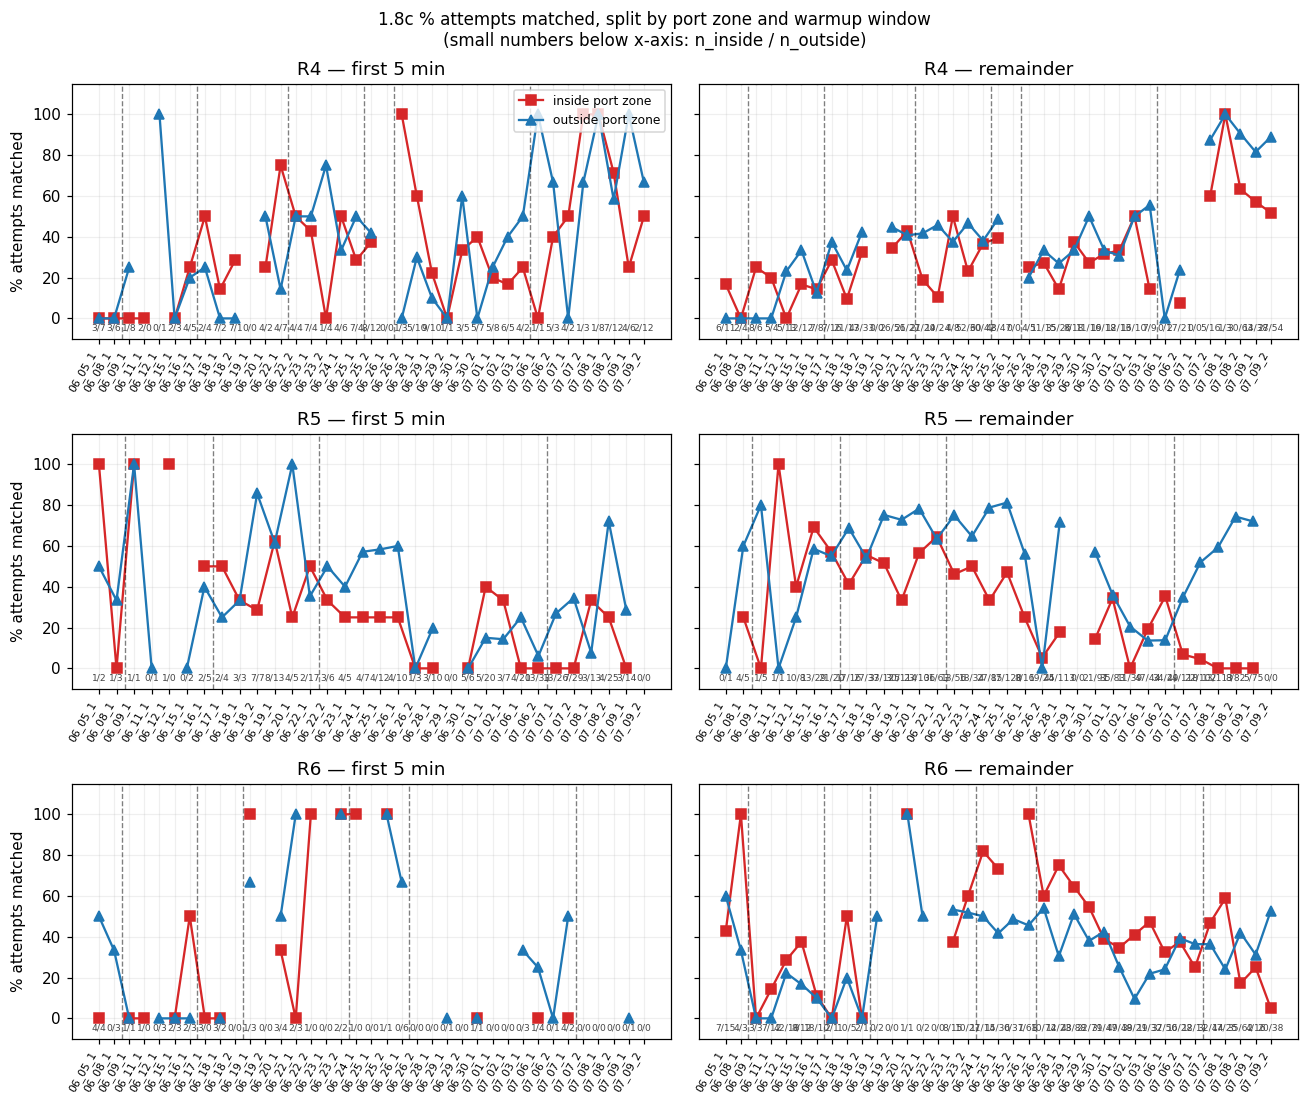

In [207]:
fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(12, 3.4 * len(rats_sorted)),
                          squeeze=False, sharey=True)
for row, rat in enumerate(rats_sorted):
    sess = by_rat[rat]
    x = np.arange(len(sess))
    states = [r['train_state'] for _, r in sess]
    for col, (mask_fn, ttl) in enumerate([
            (lambda lf: lf <  WARMUP_FRAMES, 'first 5 min'),
            (lambda lf: lf >= WARMUP_FRAMES, 'remainder')]):
        ax = axes[row, col]
        pct_in, pct_out, n_in, n_out = [], [], [], []
        for _, r in sess:
            m  = r['attempt_matched']; ip = r['attempt_inside_port']
            lf = r['attempt_lick_frame']
            keep = mask_fn(lf)
            for arr, group_mask in [((pct_in, n_in),  ip & keep),
                                     ((pct_out, n_out), ~ip & keep)]:
                n = int(group_mask.sum())
                arr[0].append(100.0 * (m & group_mask).sum() / n if n else np.nan)
                arr[1].append(n)
        ax.plot(x, pct_in,  marker='s', lw=1.5, color='#d62728',
                 label='inside port zone' if row == 0 and col == 0 else None)
        ax.plot(x, pct_out, marker='^', lw=1.5, color='#1f77b4',
                 label='outside port zone' if row == 0 and col == 0 else None)
        for xi in range(len(x)):
            ax.text(x[xi], -6, f'{n_in[xi]}/{n_out[xi]}',
                     ha='center', fontsize=6, color='#444')
        ax.set_xticks(x)
        ax.set_xticklabels([s[5:] for s, _ in sess], rotation=60, fontsize=7, ha='right')
        ax.set_ylim(-10, 115)
        ax.set_title(f'{rat} — {ttl}')
        ax.grid(alpha=0.2)
        for xt in _train_state_transitions(list(zip(x, states))):
            ax.axvline(xt, color='k', ls='--', lw=0.9, alpha=0.5)
        _train_state_dots(ax, states, x)
        if col == 0:
            ax.set_ylabel('% attempts matched')
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc='upper right')

fig.suptitle('1.8c % attempts matched, split by port zone and warmup window\n'
             '(small numbers below x-axis: n_inside / n_outside)', fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8d Attempts per 5-min bin — session × time heatmap

One heatmap per rat. Row = session (chronological, top→bottom). Column = 5-min
bin. Cell color = number of attempts in that bin. Rightmost column annotation
shows train_state (colored dot + numeric label).


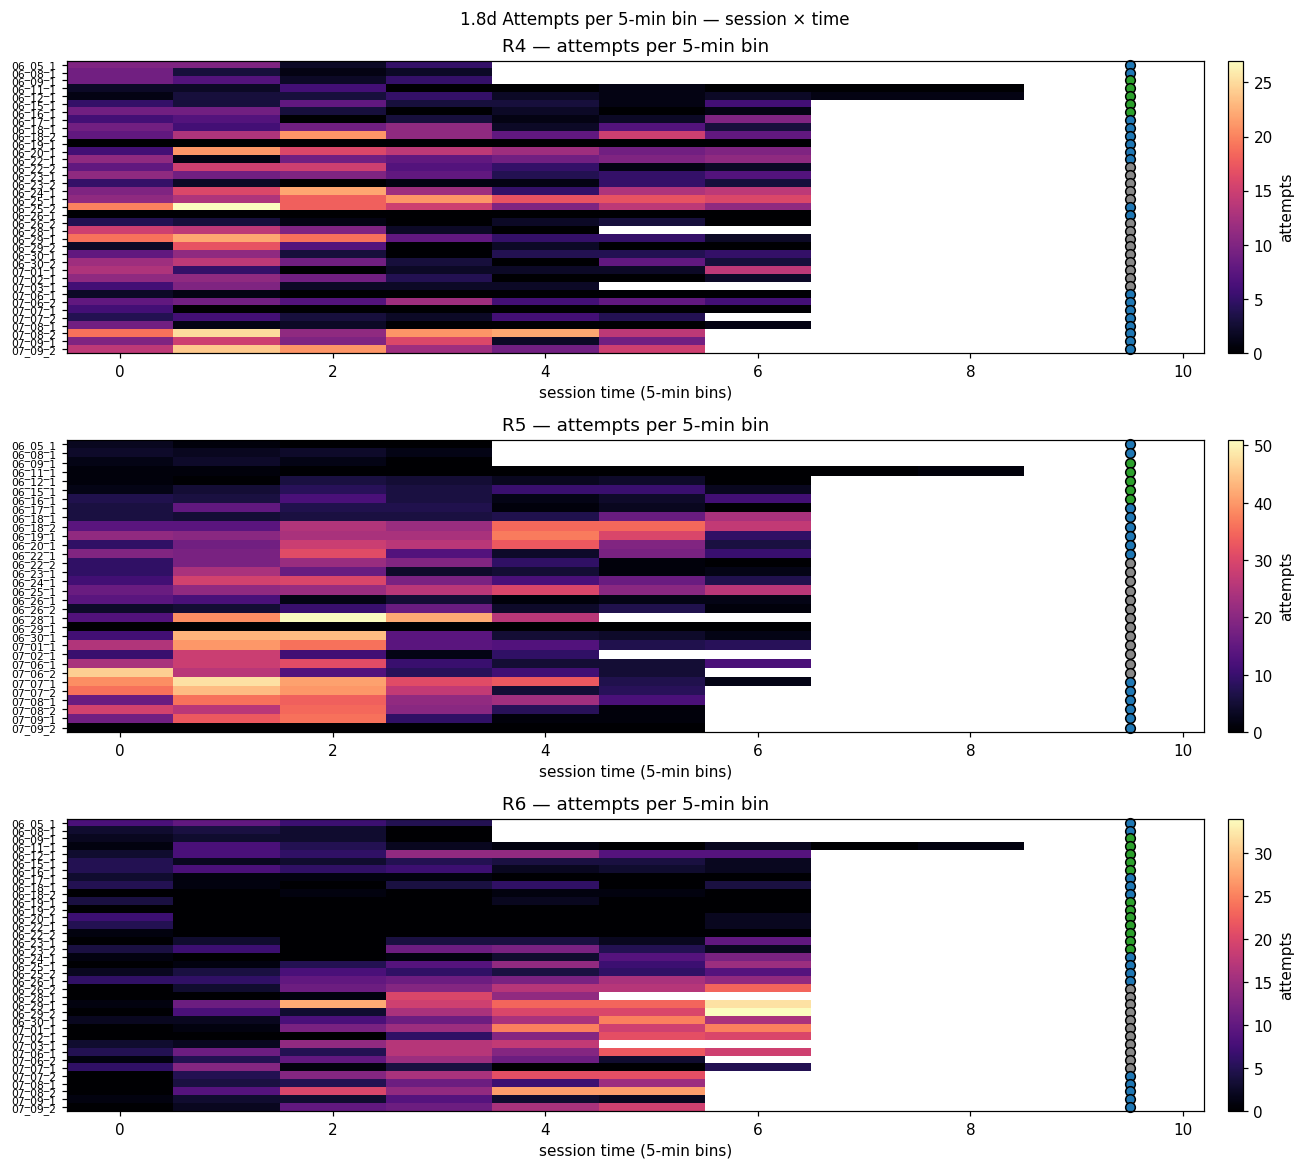

In [208]:
def _bin_counts(frames, n_frames, bin_fr=PROG_BIN_FR):
    n_bins = int(np.ceil(n_frames / bin_fr))
    if not len(frames):
        return np.zeros(n_bins), n_bins
    edges = np.arange(n_bins + 1) * bin_fr
    counts, _ = np.histogram(np.asarray(frames, dtype=int), bins=edges)
    return counts.astype(float), n_bins


def _plot_session_heatmap(ax, mat, sess, states, title, cbar_label, cmap='magma'):
    im = ax.imshow(mat, aspect='auto', cmap=cmap, origin='upper')
    ax.set_yticks(np.arange(len(sess)))
    ax.set_yticklabels([s[5:] for s, _ in sess], fontsize=7)
    ax.set_xlabel(f'session time ({int(PROG_BIN_S/60)}-min bins)')
    ax.set_title(title)
    # train_state dots at right edge
    for yi, ts in enumerate(states):
        if not np.isfinite(ts):
            ax.text(mat.shape[1] + 0.5, yi, '?', va='center', fontsize=8, color='k')
        else:
            c = TRAIN_STATE_COLOR.get(int(ts), '#000')
            ax.scatter(mat.shape[1] + 0.5, yi, marker='o', color=c, edgecolor='k',
                        s=40, clip_on=False)
    ax.set_xlim(-0.5, mat.shape[1] + 1.2)
    plt.colorbar(im, ax=ax, label=cbar_label, fraction=0.03, pad=0.02)


fig, axes = plt.subplots(len(rats_sorted), 1,
                          figsize=(12, 3.6 * len(rats_sorted)), squeeze=False)
for row, rat in enumerate(rats_sorted):
    ax = axes[row, 0]
    sess = by_rat[rat]
    # figure out max n_bins across this rat's sessions
    per_sess = []
    max_bins = 0
    states = []
    for _, r in sess:
        n_frames = len(r['sd']['triang_3d'])
        counts, nb_bins = _bin_counts(r['attempt_lick_frame'], n_frames)
        per_sess.append(counts)
        max_bins = max(max_bins, nb_bins)
        states.append(r['train_state'])
    mat = np.full((len(sess), max_bins), np.nan)
    for i, counts in enumerate(per_sess):
        mat[i, :len(counts)] = counts
    _plot_session_heatmap(ax, mat, sess, states,
                          f'{rat} — attempts per {int(PROG_BIN_S/60)}-min bin',
                          cbar_label='attempts')

fig.suptitle('1.8d Attempts per 5-min bin — session × time', fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8e % attempts matched — session × time heatmap, per port zone

Two heatmaps per rat (inside vs outside port zone). Cell color = % of attempts
in that 5-min bin whose rear was a template match. Cells with 0 attempts in the
bin are grey.


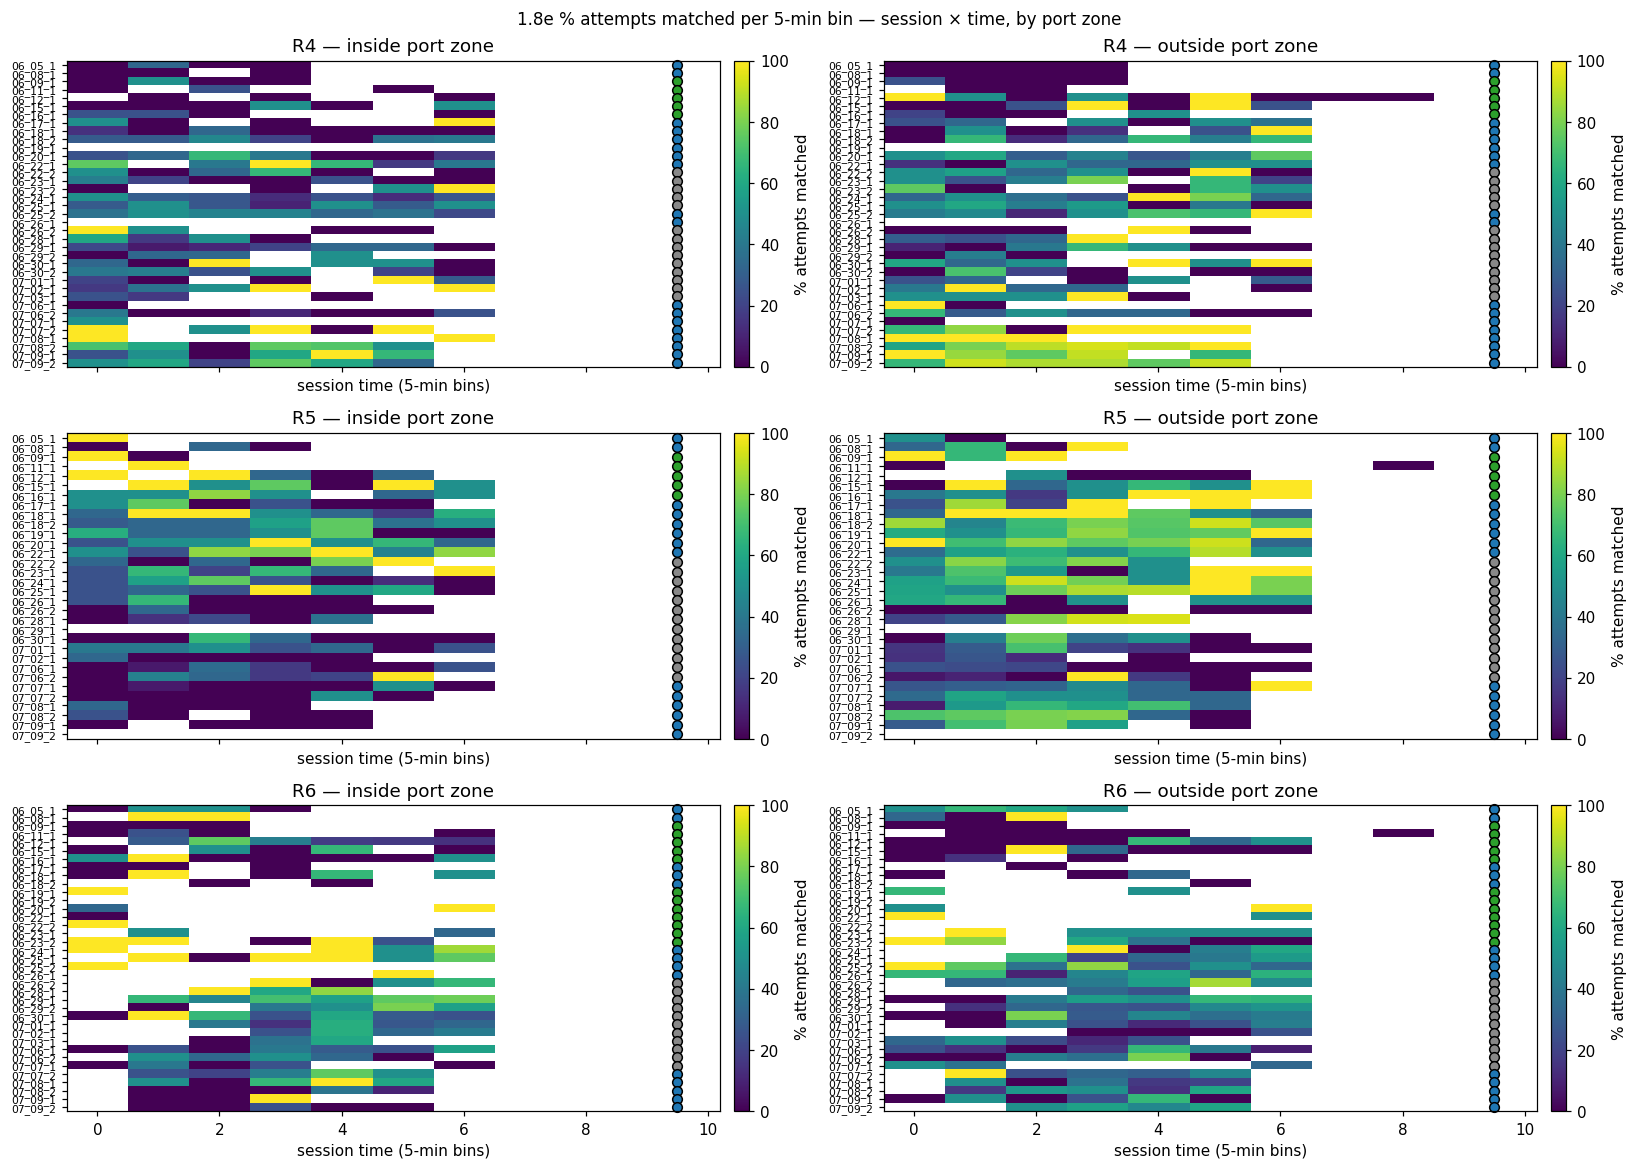

In [209]:
def _pct_matched_heatmap(sess, zone_mask_fn):
    per_sess_pct = []
    states = []
    max_bins = 0
    for _, r in sess:
        n_frames = len(r['sd']['triang_3d'])
        n_bins = int(np.ceil(n_frames / PROG_BIN_FR))
        m  = r['attempt_matched']; ip = r['attempt_inside_port']
        lf = r['attempt_lick_frame']
        zone = zone_mask_fn(ip)
        row = np.full(n_bins, np.nan)
        for k in range(n_bins):
            lo, hi = k * PROG_BIN_FR, (k + 1) * PROG_BIN_FR
            in_bin = (lf >= lo) & (lf < hi) & zone
            n = int(in_bin.sum())
            if n:
                row[k] = 100.0 * (m & in_bin).sum() / n
        per_sess_pct.append(row)
        max_bins = max(max_bins, n_bins)
        states.append(r['train_state'])
    mat = np.full((len(sess), max_bins), np.nan)
    for i, row in enumerate(per_sess_pct):
        mat[i, :len(row)] = row
    return mat, states


fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(15, 3.6 * len(rats_sorted)),
                          squeeze=False, sharex=True)
for row, rat in enumerate(rats_sorted):
    sess = by_rat[rat]
    for col, (mask_fn, ttl) in enumerate([
            (lambda ip: ip,   'inside port zone'),
            (lambda ip: ~ip, 'outside port zone')]):
        mat, states = _pct_matched_heatmap(sess, mask_fn)
        ax = axes[row, col]
        # Use a diverging or fixed 0-100 colormap so cells are comparable.
        im = ax.imshow(mat, aspect='auto', cmap='viridis', vmin=0, vmax=100,
                        origin='upper')
        ax.set_yticks(np.arange(len(sess)))
        ax.set_yticklabels([s[5:] for s, _ in sess], fontsize=7)
        ax.set_xlabel(f'session time ({int(PROG_BIN_S/60)}-min bins)')
        ax.set_title(f'{rat} — {ttl}')
        for yi, ts in enumerate(states):
            if not np.isfinite(ts):
                ax.text(mat.shape[1] + 0.5, yi, '?', va='center', fontsize=8, color='k')
            else:
                c = TRAIN_STATE_COLOR.get(int(ts), '#000')
                ax.scatter(mat.shape[1] + 0.5, yi, marker='o', color=c, edgecolor='k',
                            s=40, clip_on=False)
        ax.set_xlim(-0.5, mat.shape[1] + 1.2)
        plt.colorbar(im, ax=ax, label='% attempts matched', fraction=0.03, pad=0.02)

fig.suptitle('1.8e % attempts matched per 5-min bin — session × time, by port zone',
             fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8f Matched-rear mean trajectory per session (chronology-colored)

For each session, take the mean PC1/PC2 trajectory across all matched rears'
max-alignment windows. Plot one curve per session, colored by chronological
order (early=blue, late=red). Template band shaded for reference. If the
matched-rear shape drifts across training, you'll see the colors sweep across
the band.


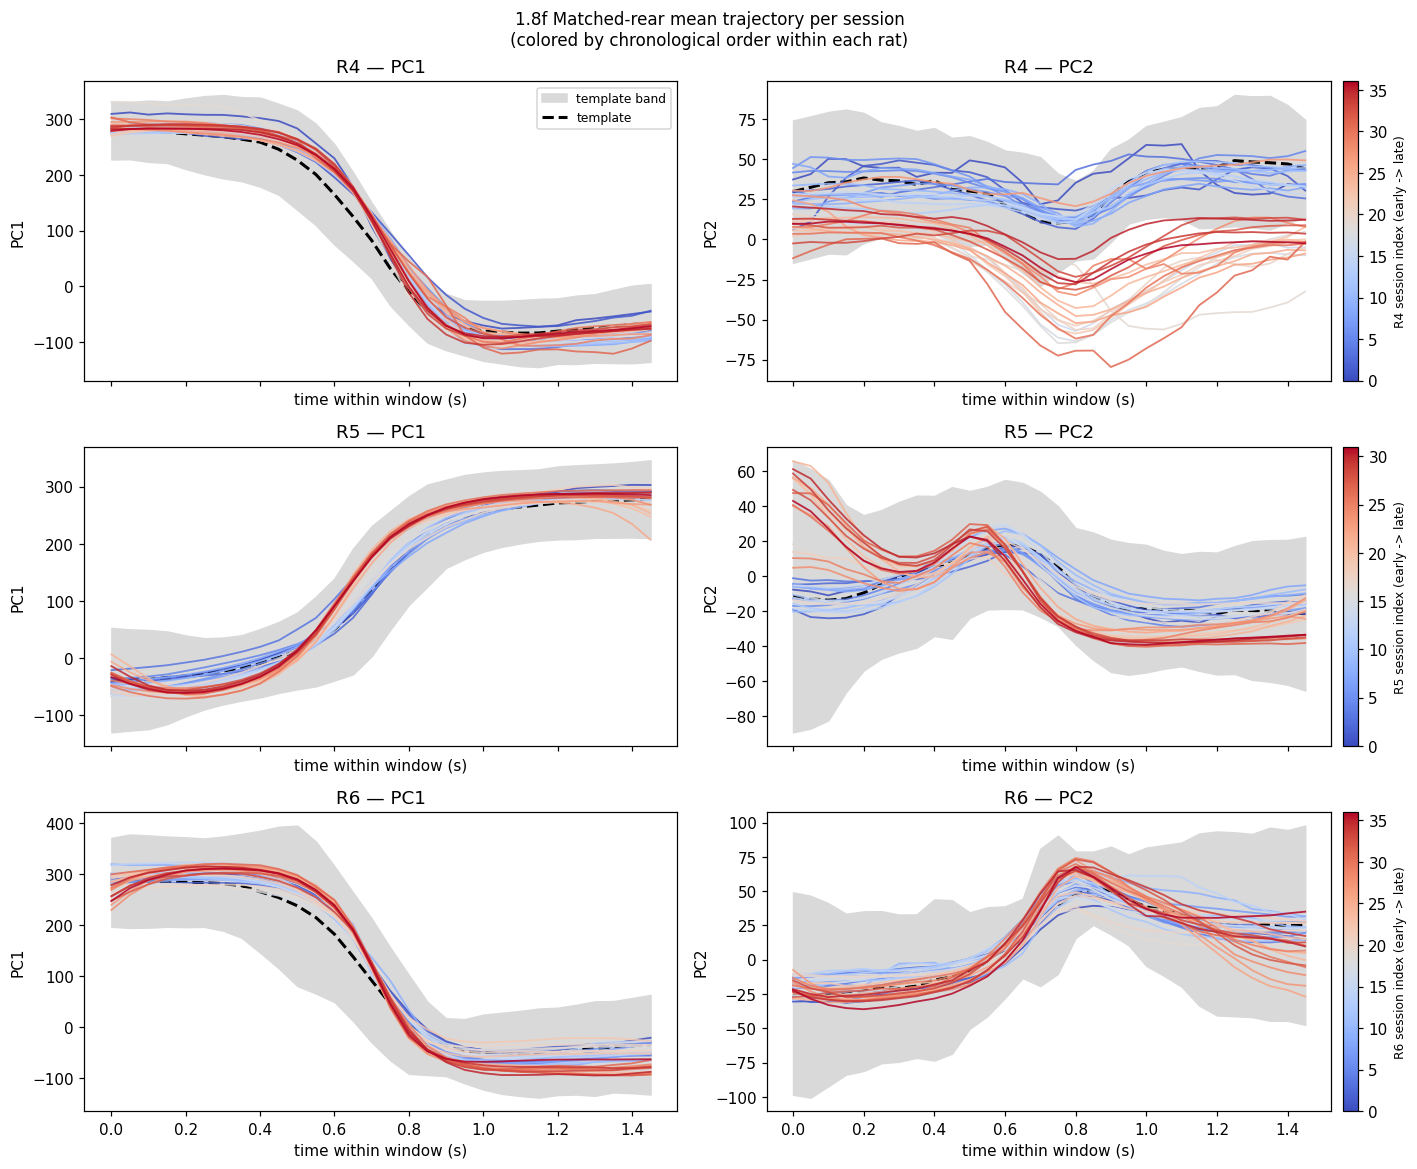

In [210]:
from matplotlib import cm
from matplotlib.colors import Normalize

fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(13, 3.6 * len(rats_sorted)),
                          squeeze=False, sharex=True)
for row, rat in enumerate(rats_sorted):
    sess = by_rat[rat]
    n_sess = len(sess)
    norm = Normalize(vmin=0, vmax=max(n_sess - 1, 1))
    cmap = plt.get_cmap('coolwarm')
    for col, (pidx, label) in enumerate([(0, 'PC1'), (1, 'PC2')]):
        ax = axes[row, col]
        # Use template + bounds from the FIRST session (they can differ across
        # template rebuilds, but the band shape is what we're comparing to).
        pc_template = sess[0][1]['pc_template']
        bounds     = sess[0][1]['bounds_to_use']
        t_axis     = np.arange(TEMPLATE_LEN) / SLEAP_HZ
        center     = pc_template[:, pidx]
        band       = bounds[:, pidx]
        ax.fill_between(t_axis, center - band, center + band, color='0.85',
                         label='template band' if col == 0 else None)
        ax.plot(t_axis, center, 'k--', lw=2, label='template' if col == 0 else None)
        for k, (s, r) in enumerate(sess):
            ok = (r['rear_align_end'] >= 0) & r['rear_matched']
            if not ok.any():
                continue
            ends = r['rear_align_end'][ok]
            pcs = r['pcs_used']
            segs = np.stack([pcs[e - TEMPLATE_LEN + 1:e + 1, pidx] for e in ends])
            ax.plot(t_axis, segs.mean(axis=0), lw=1.2, color=cmap(norm(k)),
                     alpha=0.85)
        ax.set_xlabel('time within window (s)')
        ax.set_ylabel(label)
        ax.set_title(f'{rat} — {label}')
        if col == 0 and row == 0:
            ax.legend(fontsize=8, loc='best')
    # Attach chronology colorbar to the right (PC2) panel only so
    # tight_layout can size it correctly.
    sm = cm.ScalarMappable(norm=Normalize(vmin=0, vmax=max(n_sess - 1, 1)), cmap=cmap)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes[row, 1], fraction=0.03, pad=0.02)
    cb.set_label(f'{rat} session index (early -> late)', fontsize=8)

fig.suptitle('1.8f Matched-rear mean trajectory per session\n'
             '(colored by chronological order within each rat)',
             fontsize=11)
fig.tight_layout()
plt.show()


#### 1.8g Per-session medians — rear→lick latency and alignment offset

Two summary metrics per session:

- **Rear→lick latency** (attempts only): median seconds from rear end to
  attaching lick bout.
- **Alignment offset**: median (alignment-end − rear-end) in seconds. Negative =
  best-aligned window ends before the rear ends; positive = ends in the buffer
  after the rear. Bimodal → template is finding two phases.


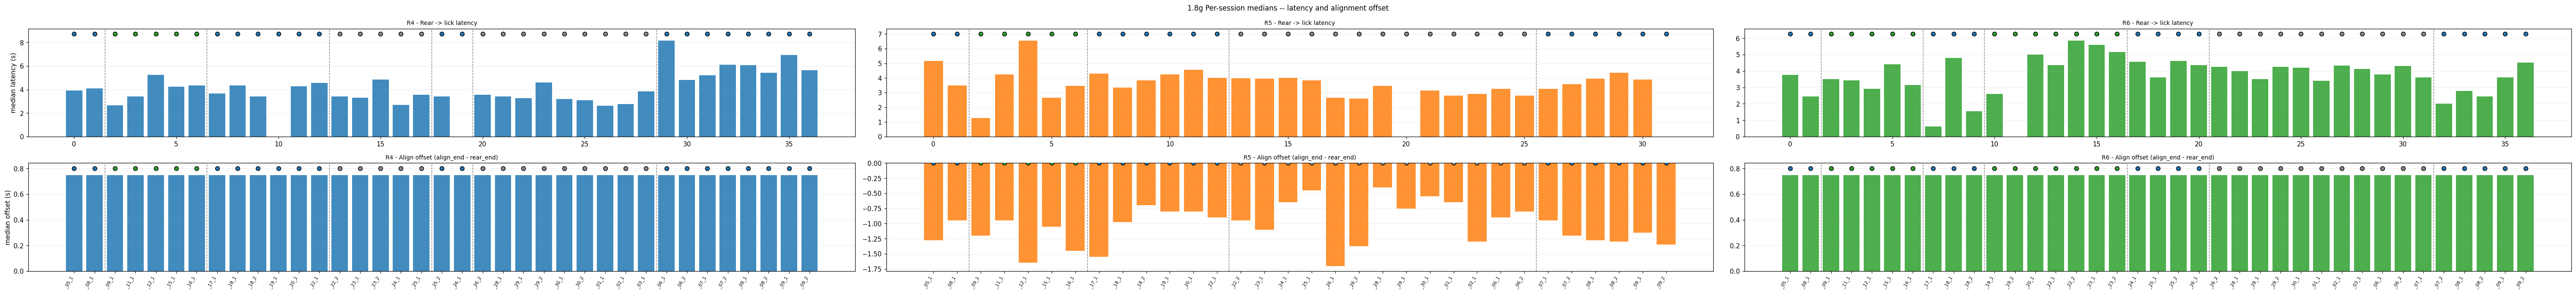

In [211]:
# 1.8g Per-session medians -- latency & alignment offset, one COLUMN per rat.
_rats = [rt for rt in rats_sorted if any(k[0] == rt for k in RESULTS)]
fig, axes = plt.subplots(2, len(_rats),
                         figsize=(max(4.5, 0.5 * max(
                             (sum(1 for k in RESULTS if k[0] == rt) for rt in _rats),
                             default=1)) * len(_rats), 6.4),
                         squeeze=False, sharex=False)
for col, rat in enumerate(_rats):
    _sk = sorted(s for (rt, s) in RESULTS if rt == rat)
    labels, lat_med, off_med, states = [], [], [], []
    for s in _sk:
        r = RESULTS[(rat, s)]
        labels.append(s[-5:]); states.append(r['train_state'])
        if len(r['attempt_rear_idx']):
            lat_s = (r['attempt_lick_frame'] - r['rear_end'][r['attempt_rear_idx']]) / SLEAP_HZ
            lat_med.append(float(np.median(lat_s)))
        else:
            lat_med.append(np.nan)
        ok = r['rear_align_end'] >= 0
        off_med.append(float(np.median(
            (r['rear_align_end'][ok] - r['rear_end'][ok]) / SLEAP_HZ)) if ok.any() else np.nan)
    x = np.arange(len(labels))
    _color = RAT_COLOR.get(rat, '#888')
    for row, (ys, ylabel, ttl) in enumerate([
            (lat_med, 'median latency (s)', 'Rear -> lick latency'),
            (off_med, 'median offset (s)',  'Align offset (align_end - rear_end)')]):
        ax = axes[row, col]
        ax.bar(x, np.nan_to_num(ys, nan=0), color=_color, alpha=0.85)
        ax.set_title(f'{rat} - {ttl}', fontsize=9)
        ax.grid(axis='y', alpha=0.2)
        if col == 0:
            ax.set_ylabel(ylabel)
        # per-rat train-state transitions + dots
        for xt in _train_state_transitions(list(zip(range(len(states)), states))):
            ax.axvline(xt, color='k', ls='--', lw=0.9, alpha=0.5)
        _train_state_dots(ax, states, x)
        if row == 1:
            ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=7, ha='right')
fig.suptitle('1.8g Per-session medians -- latency and alignment offset', fontsize=11)
fig.tight_layout(); plt.show()


#### 1.8h Condition breakdown — pooled by train_state

Aggregate across sessions grouped by `train_state` (per rat). For each state:

- **Total rears / lick bouts / attempts** per session (box plot).
- **% attempts matched** per session (box plot).
- **Matched-rear mean ± std trajectory** overlaid across states.

Sessions with `train_state` missing are excluded from these panels.


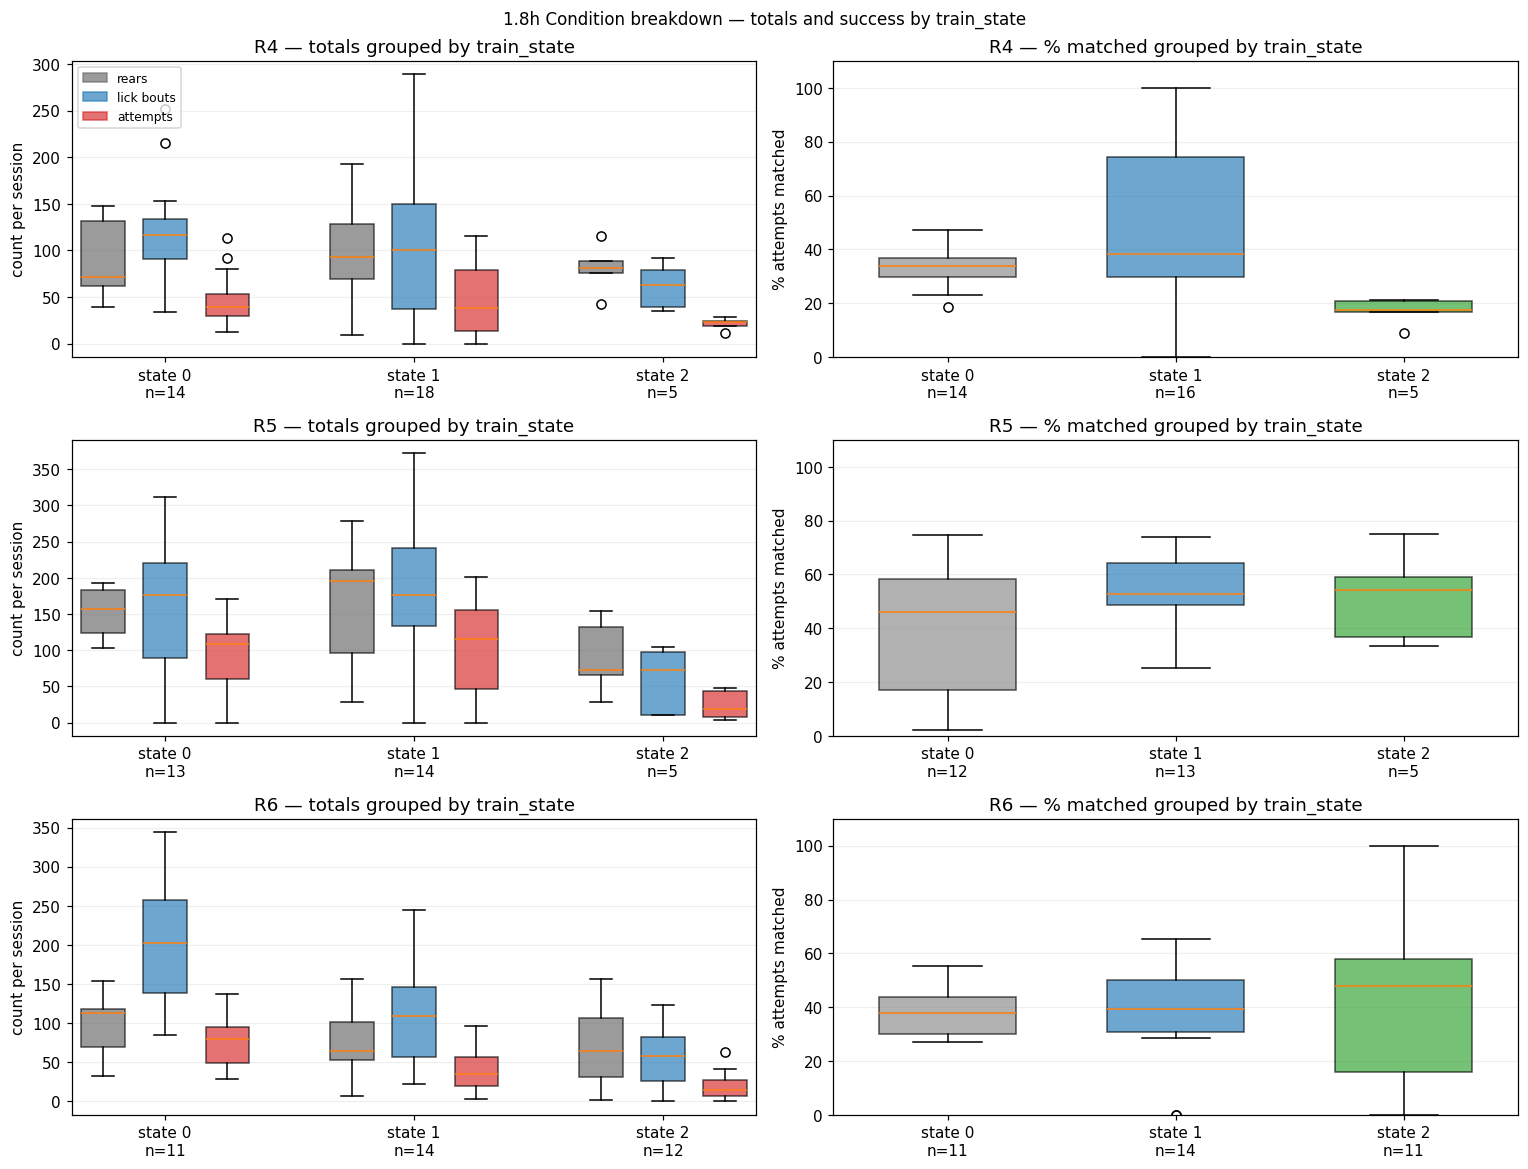

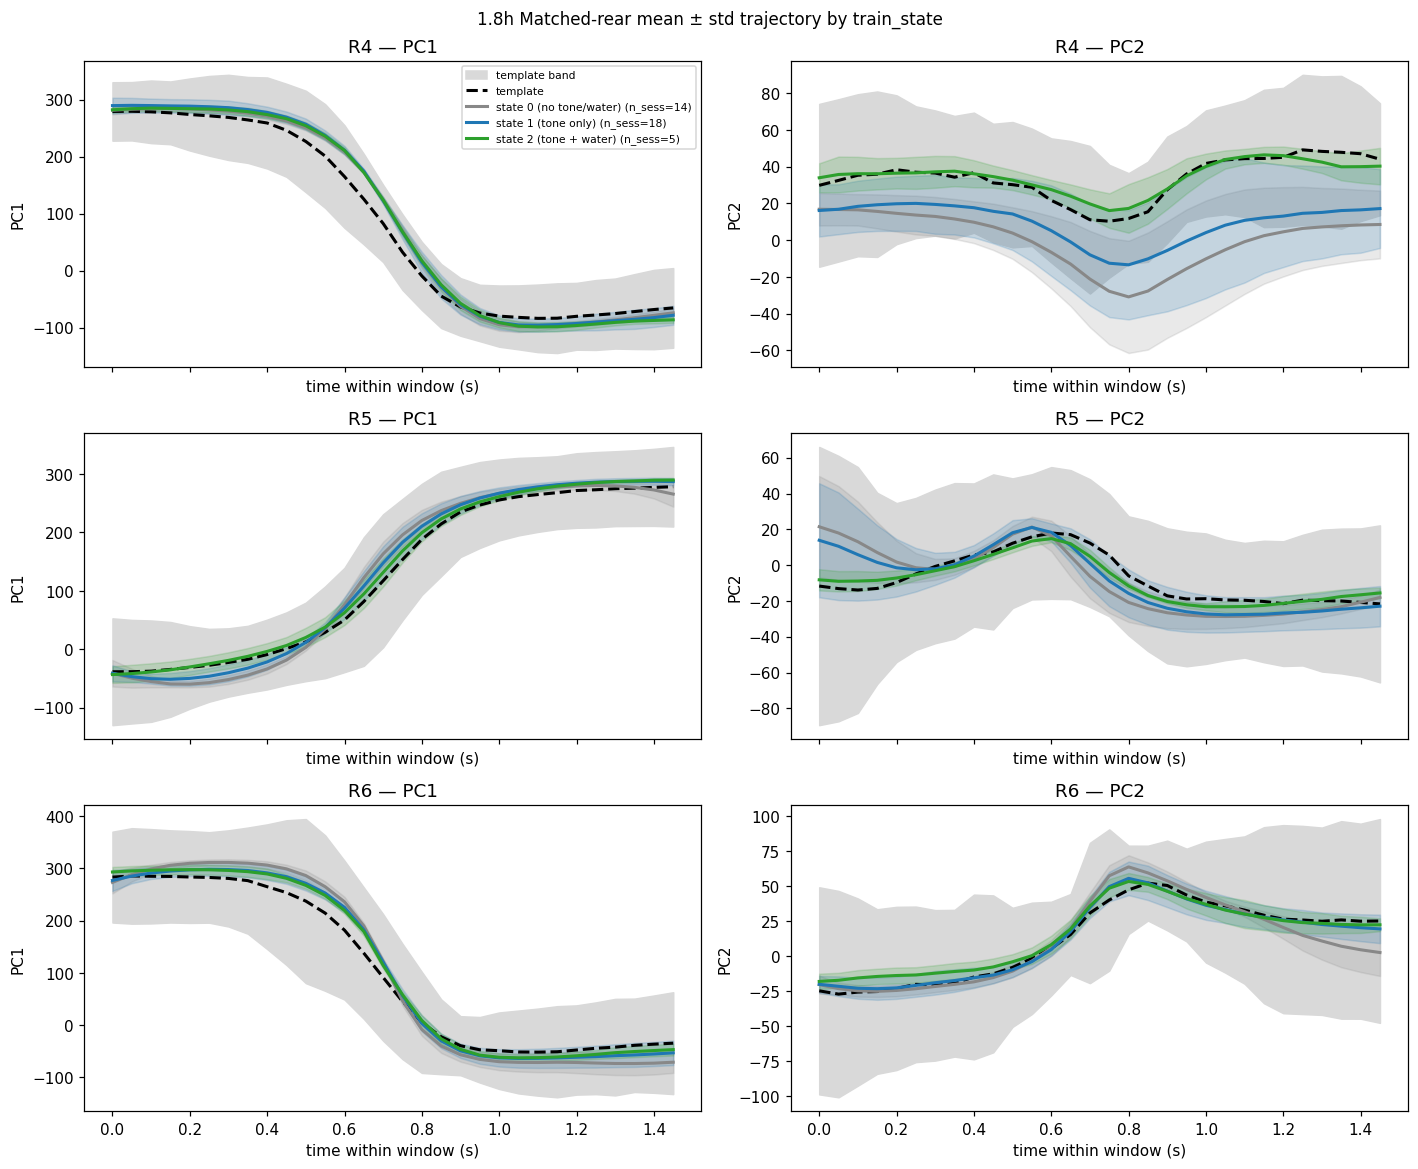

In [212]:
# --- collect per-session scalar summaries + trajectories by (rat, state) ---
per_rat_state = {}   # (rat, state) -> dict of arrays
for (rat, s), r in RESULTS.items():
    ts = r['train_state']
    if not np.isfinite(ts):
        continue
    key = (rat, int(ts))
    d = per_rat_state.setdefault(key, {
        'rears': [], 'bouts': [], 'attempts': [], 'pct_match': [],
        'trajs_pc1': [], 'trajs_pc2': [],
    })
    d['rears'].append(len(r['rears']))
    d['bouts'].append(len(r['lick_bout_frames']))
    d['attempts'].append(len(r['attempt_rear_idx']))
    n_a = len(r['attempt_rear_idx'])
    d['pct_match'].append(100.0 * int(r['attempt_matched'].sum()) / n_a if n_a else np.nan)
    ok = (r['rear_align_end'] >= 0) & r['rear_matched']
    if ok.any():
        ends = r['rear_align_end'][ok]
        pcs = r['pcs_used']
        segs = np.stack([pcs[e - TEMPLATE_LEN + 1:e + 1, :2] for e in ends])
        d['trajs_pc1'].append(segs[:, :, 0].mean(axis=0))
        d['trajs_pc2'].append(segs[:, :, 1].mean(axis=0))

STATES = sorted({s for _, s in per_rat_state.keys()})

# ---- Panel A: totals + % matched box plots ----
fig, axes = plt.subplots(len(rats_sorted), 2, figsize=(14, 3.6 * len(rats_sorted)),
                          squeeze=False)
for row, rat in enumerate(rats_sorted):
    # Totals grouped bar-of-boxes
    ax = axes[row, 0]
    positions = []
    data = []
    tick_labels = []
    tick_pos = []
    for i, state in enumerate(STATES):
        d = per_rat_state.get((rat, state))
        if d is None or not d['rears']:
            continue
        base = i * 4
        for j, (arr, name) in enumerate([
                (d['rears'],   'rears'),
                (d['bouts'],   'bouts'),
                (d['attempts'],'attempts')]):
            positions.append(base + j)
            data.append(arr)
        tick_labels.append(f'state {state}\nn={len(d["rears"])}')
        tick_pos.append(base + 1)
    if data:
        bp = ax.boxplot(data, positions=positions, widths=0.7, patch_artist=True)
        colors_per_bar = ['#666', '#1f77b4', '#d62728'] * len(STATES)
        for patch, c in zip(bp['boxes'], colors_per_bar[:len(bp['boxes'])]):
            patch.set_facecolor(c); patch.set_alpha(0.65)
        ax.set_xticks(tick_pos)
        ax.set_xticklabels(tick_labels)
    ax.set_ylabel('count per session')
    ax.set_title(f'{rat} — totals grouped by train_state')
    ax.grid(axis='y', alpha=0.2)

    # % attempts matched
    ax2 = axes[row, 1]
    pct_data, pos, tlabels = [], [], []
    for i, state in enumerate(STATES):
        d = per_rat_state.get((rat, state))
        if d is None or not d['pct_match']:
            continue
        vals = np.asarray([v for v in d['pct_match'] if np.isfinite(v)])
        if not len(vals): continue
        pct_data.append(vals)
        pos.append(i)
        tlabels.append(f'state {state}\nn={len(vals)}')
    if pct_data:
        bp2 = ax2.boxplot(pct_data, positions=pos, widths=0.6, patch_artist=True)
        for patch, state in zip(bp2['boxes'], [STATES[i] for i in pos]):
            patch.set_facecolor(TRAIN_STATE_COLOR.get(int(state), '#888'))
            patch.set_alpha(0.65)
        ax2.set_xticks(pos)
        ax2.set_xticklabels(tlabels)
    ax2.set_ylabel('% attempts matched')
    ax2.set_ylim(0, 110)
    ax2.set_title(f'{rat} — % matched grouped by train_state')
    ax2.grid(axis='y', alpha=0.2)

# Add a manual legend for the totals sub-plots
from matplotlib.patches import Patch
handles = [Patch(color='#666', alpha=0.65, label='rears'),
            Patch(color='#1f77b4', alpha=0.65, label='lick bouts'),
            Patch(color='#d62728', alpha=0.65, label='attempts')]
axes[0, 0].legend(handles=handles, fontsize=8, loc='upper left')
fig.suptitle('1.8h Condition breakdown — totals and success by train_state',
             fontsize=11)
fig.tight_layout()
plt.show()

# ---- Panel B: matched-rear mean trajectories by state, per rat ----
fig, axes = plt.subplots(len(rats_sorted), 2,
                          figsize=(13, 3.6 * len(rats_sorted)),
                          squeeze=False, sharex=True)
t_axis = np.arange(TEMPLATE_LEN) / SLEAP_HZ
for row, rat in enumerate(rats_sorted):
    # get a representative template band from any session
    pc_template = by_rat[rat][0][1]['pc_template']
    bounds = by_rat[rat][0][1]['bounds_to_use']
    for col, (pidx, label) in enumerate([(0, 'PC1'), (1, 'PC2')]):
        ax = axes[row, col]
        center = pc_template[:, pidx]
        band = bounds[:, pidx]
        ax.fill_between(t_axis, center - band, center + band, color='0.85',
                         label='template band' if col == 0 else None)
        ax.plot(t_axis, center, 'k--', lw=2, label='template' if col == 0 else None)
        for state in STATES:
            d = per_rat_state.get((rat, state))
            if d is None: continue
            trajs_key = 'trajs_pc1' if pidx == 0 else 'trajs_pc2'
            trajs = d[trajs_key]
            if not trajs: continue
            trajs = np.stack(trajs)
            m = trajs.mean(axis=0); s = trajs.std(axis=0)
            c = TRAIN_STATE_COLOR.get(int(state), '#000')
            ax.plot(t_axis, m, lw=2, color=c,
                     label=f'{TRAIN_STATE_LABEL[state]} (n_sess={len(trajs)})')
            ax.fill_between(t_axis, m - s, m + s, color=c, alpha=0.18)
        ax.set_xlabel('time within window (s)')
        ax.set_ylabel(label)
        ax.set_title(f'{rat} — {label}')
        if col == 0 and row == 0:
            ax.legend(fontsize=7, loc='best')
fig.suptitle('1.8h Matched-rear mean ± std trajectory by train_state',
             fontsize=11)
fig.tight_layout()
plt.show()


## Section 2 — SLEAP + DANNCE cross-session analyses

Only runs on sessions that also have `processed/sleap_dannce_keys.*`.
The per-session analyses mirror the single-session notebook:

1. Use the session's saved `pc_template` + `bounds_to_use` to find SLEAP offline
   matches.
2. Rebuild SLEAP and DANNCE templates from those matches (mean over the
   30-frame windows of the matched PC trajectories).
3. Re-match with the rebuilt templates on both SLEAP and DANNCE PCs.
4. Score overlap: SLEAP-only, DANNCE-only, both (within ±10 frames).
5. Per-session keypoint MSE and PC MSE.
6. Per-session calibration health: mean reprojection residual for the 3D SLEAP
   keypoints, averaged over the 3 cameras.


In [215]:
def get_template_match_indices(keys_pcs, pc_template, pc_template_bounds,
                                refractory_frames=None, accepted_errors=3):
    """Vectorized template matcher. Same per-frame semantics as the online
    rule (passes when the count of out-of-bounds (frame, PC) samples in the
    window is <= accepted_errors) and the same refractory rule (>= refractory_frames
    between matches). Returns (match_indices, num_outside_per_frame).
    """
    pcs = np.asarray(keys_pcs)
    template = np.asarray(pc_template)
    bounds = np.asarray(pc_template_bounds)
    L = template.shape[0]
    T = pcs.shape[0]
    num_outside = np.full(T, np.nan)
    if refractory_frames is None:
        refractory_frames = L
    if T < L:
        return [], num_outside
    base = np.arange(T - L + 1)[:, None]
    win = pcs[base + np.arange(L)]
    above = win >= (template + bounds)
    below = win <= (template - bounds)
    outside = (above | below).reshape(win.shape[0], -1).sum(axis=1)
    num_outside[L - 1:] = outside
    passes = outside <= accepted_errors
    matches, last = [], -refractory_frames
    for k in range(len(passes)):
        if passes[k]:
            t = k + L - 1
            if t - last >= refractory_frames:
                matches.append(t)
                last = t
    return matches, num_outside


def correct_matches(pcs, pc_template, matches, buffer_frames=30):
    """Re-center each match on the locally best-aligned 30-frame window."""
    pcs = np.asarray(pcs); pc_template = np.asarray(pc_template)
    matches = np.asarray(list(matches), dtype=int)
    L = pc_template.shape[0]; n_pcs = pc_template.shape[1]
    T = pcs.shape[0]
    out = matches.copy()
    for i, m in enumerate(matches):
        e_min = max(m - buffer_frames, L - 1)
        e_max = min(m + buffer_frames, T - 1)
        if e_max < e_min:
            continue
        ends = np.arange(e_min, e_max + 1)
        starts = ends - (L - 1)
        idx = starts[:, None] + np.arange(L)[None, :]
        windows = pcs[idx, :n_pcs]
        diff = windows - pc_template[None, :, :]
        mse = (diff ** 2).mean(axis=(1, 2))
        out[i] = int(ends[int(np.argmin(mse))])
    return out


def closest_match(source_idx, target_idx):
    return np.array([np.argmin(np.abs(np.array(source_idx) - t)) for t in target_idx])


def get_match_overlap(dannce_matches, sleap_matches, thresh=10):
    sleap_only = np.array([], dtype=int)
    dannce_only = np.array([], dtype=int)
    both = np.array([], dtype=int)
    if len(dannce_matches) == 0 and len(sleap_matches) == 0:
        return sleap_only, dannce_only, both
    if len(dannce_matches) == 0:
        return np.asarray(sleap_matches), dannce_only, both
    if len(sleap_matches) == 0:
        return sleap_only, np.asarray(dannce_matches), both
    s = np.asarray(sleap_matches); d = np.asarray(dannce_matches)
    c_for_s = closest_match(d, s)   # idx into d closest to each s
    c_for_d = closest_match(s, d)   # idx into s closest to each d
    both        = s[np.where(np.abs(s - d[c_for_s]) <  thresh)[0]]
    sleap_only  = s[np.where(np.abs(s - d[c_for_s]) >= thresh)[0]]
    dannce_only = d[np.where(np.abs(d - s[c_for_d]) >= thresh)[0]]
    return sleap_only, dannce_only, both


In [216]:
def _has_processed(rat, session):
    local = f'/home/yutaka-sprague/CLIRB/data/sleap_dannce_keys_2026_02_18/{rat}/{session}/sleap_dannce_keys.mat'
    smb   = os.path.join(DATA_ROOT, rat, session, 'processed', 'sleap_dannce_keys.mat')
    return os.path.isfile(local) or os.path.isfile(smb)


def analyse_dual_session(rat, session, sd, n_components=N_COMPONENTS,
                         template_length=TEMPLATE_LEN):
    """Returns dict with overlap counts, kp/PC MSE arrays, and the underlying
    arrays needed by callers. None if data is unavailable."""
    _c = sc.get_raw_session(rat, session, want_dual=True)
    if _c is None or not _c['has_dual']:
        print(f'  {rat}/{session}: dual data unavailable — skipping')
        return None
    keys = {'sleap_keys_3D': _c['sleap_keys_3D'],
            'dannce_keys_3D': _c['dannce_keys_3D']}
    aligned = {'dannce_idx_for_sleap_cams': _c['dannce_idx_for_sleap_cams']}

    # Online-equivalent pipeline: DO NOT apply median_filter to raw keypoints.
    # The 5-frame CAUSAL median goes AFTER normalize (below).
    sleap_3d = keys['sleap_keys_3D']
    dannce_3d = keys['dannce_keys_3D']
    if dannce_3d.ndim == 4:
        dannce_3d = dannce_3d.squeeze(axis=1).transpose(0, 2, 1)
    else:
        dannce_3d = np.transpose(dannce_3d, [0, 2, 1])
    aligned_idx = aligned['dannce_idx_for_sleap_cams'].astype(int).ravel()[1:]
    dannce_3d = dannce_3d[aligned_idx, :, :]

    # Templates straight from the session's saved npz (so bounds match what
    # the online rule was using on this date).
    tmpl = sd['template']
    pc_template      = tmpl['template'][:, :n_components]
    pc_weights       = tmpl['pc_weights']
    feature_means    = tmpl['feature_means']
    bounds_to_use    = tmpl['bounds_to_use']
    dannce_template  = tmpl['dannce_template'][:, :n_components]
    dannce_bounds    = tmpl['dannce_template_bounds'][:, :n_components]

    # Project both modalities through the same pc_weights / feature_means.
    # Match the online rule: flip z (SLEAP only) -> normalize per-frame ->
    # 5-frame CAUSAL median in rotated-keypoint space -> project.
    sleap_flipped = sleap_3d.astype(np.float32).copy()
    sleap_flipped[:, :, 2] = -sleap_flipped[:, :, 2]
    sleap_rotated, _, _ = normalize_skeleton_batch(sleap_flipped)
    sleap_rotated_med = _causal_median_5_kp(sleap_rotated)

    dannce_rotated, _, _ = normalize_skeleton_batch(dannce_3d.astype(np.float32))
    dannce_rotated_med = _causal_median_5_kp(dannce_rotated)

    sleap_pcs  = project_to_pcs(sleap_rotated_med,  pc_weights, feature_means)
    dannce_pcs = project_to_pcs(dannce_rotated_med, pc_weights, feature_means)

    # --- Pass 1: find SLEAP matches with the saved per-frame bounds.
    sleap_matches, _ = get_template_match_indices(
        sleap_pcs[:, :n_components], pc_template, bounds_to_use,
        refractory_frames=template_length)
    sleap_corr = correct_matches(sleap_pcs, pc_template, sleap_matches)

    if len(sleap_corr) == 0:
        return {
            'sleap_pcs': sleap_pcs, 'dannce_pcs': dannce_pcs,
            'sleap_rotated': sleap_rotated_med, 'dannce_rotated': dannce_rotated_med,
            'sleap_only': np.array([], dtype=int),
            'dannce_only': np.array([], dtype=int),
            'both': np.array([], dtype=int),
            'sleap_matches_new': np.array([], dtype=int),
            'dannce_matches_new': np.array([], dtype=int),
            'pc_mse_all': np.array([]), 'kp_dist_all': np.array([]),
            'n_sleap_initial': 0,
        }

    # --- Pass 2: rebuild SLEAP/DANNCE templates from those matches, re-match.
    sleap_segs  = np.array([sleap_pcs [m - template_length + 1:m + 1, :n_components]
                             for m in sleap_corr])
    dannce_segs = np.array([dannce_pcs[m - template_length + 1:m + 1, :n_components]
                             for m in sleap_corr])
    sleap_rebuild_t   = sleap_segs.mean(axis=0)
    sleap_rebuild_std = sleap_segs.std(axis=0)
    dannce_rebuild_t  = dannce_segs.mean(axis=0)
    dannce_rebuild_std = dannce_segs.std(axis=0)
    rebuild_std = sleap_rebuild_std + dannce_rebuild_std

    sleap_matches_new, _ = get_template_match_indices(
        sleap_pcs[:, :n_components], sleap_rebuild_t, rebuild_std,
        refractory_frames=template_length)
    dannce_matches_new, _ = get_template_match_indices(
        dannce_pcs[:, :n_components], dannce_rebuild_t, rebuild_std,
        refractory_frames=template_length)
    sleap_matches_new = correct_matches(sleap_pcs,  sleap_rebuild_t,  sleap_matches_new)
    dannce_matches_new = correct_matches(dannce_pcs, dannce_rebuild_t, dannce_matches_new)

    sleap_only, dannce_only, both = get_match_overlap(
        dannce_matches_new, sleap_matches_new, thresh=10)

    # --- Per-match PC MSE and keypoint distance, pooled over ALL matches
    # (sleap-only + dannce-only + both) so the per-session number is one scalar.
    all_matches = np.concatenate([sleap_only, dannce_only, both]).astype(int)
    pc_mse, kp_dist = [], []
    for m in all_matches:
        s = int(m) - template_length + 1
        e = int(m) + 1
        if s < 0 or e > min(len(sleap_pcs), len(dannce_pcs)):
            continue
        pc_mse.append(((sleap_pcs[s:e, :n_components] - dannce_pcs[s:e, :n_components]) ** 2).mean())
        kp_dist.append(np.linalg.norm(sleap_rotated_med[s:e] - dannce_rotated_med[s:e], axis=-1).mean())
    return {
        'sleap_pcs': sleap_pcs, 'dannce_pcs': dannce_pcs,
        'sleap_rotated': sleap_rotated_med, 'dannce_rotated': dannce_rotated_med,
        'sleap_only': sleap_only,
        'dannce_only': dannce_only,
        'both': both,
        'sleap_matches_new': sleap_matches_new,
        'dannce_matches_new': dannce_matches_new,
        'pc_mse_all': np.asarray(pc_mse),
        'kp_dist_all': np.asarray(kp_dist),
        'n_sleap_initial': len(sleap_matches),
    }


DUAL = {}
for (rat, s) in SESSIONS:
    if (rat, s) not in RESULTS:
        continue
    if not _has_processed(rat, s):
        continue
    sd = RESULTS[(rat, s)]['sd']
    _dt = sd['template'].get('dannce_template') if 'dannce_template' in sd['template'] else None
    if _dt is None or np.ndim(_dt) < 2 or _dt.shape[0] == 0:
        # Skip if the template has no DANNCE template, or an EMPTY/1-D one:
        # later per-session templates (e.g. R5_template_3/4, R6_template_2) were
        # saved SLEAP-only with dannce_template = shape (0,), which would crash
        # analyse_dual_session's dannce_template[:, :n_components] indexing.
        print(f'  {rat}/{s}: template lacks a usable dannce_template — skipping dual analysis')
        continue
    res = analyse_dual_session(rat, s, sd)
    if res is None:
        continue
    DUAL[(rat, s)] = res
    print(f"{rat}/{s}: sleap_only={len(res['sleap_only'])}  "
          f"dannce_only={len(res['dannce_only'])}  both={len(res['both'])}")
print(f'dual-modality sessions analysed: {len(DUAL)}')


R4/2026_06_05_1: sleap_only=1  dannce_only=0  both=3
R4/2026_06_08_1: sleap_only=2  dannce_only=3  both=3
R4/2026_06_09_1: sleap_only=6  dannce_only=3  both=9
  R4/2026_06_11_1: template lacks a usable dannce_template — skipping dual analysis
R4/2026_06_12_1: sleap_only=8  dannce_only=0  both=11
R4/2026_06_15_1: sleap_only=8  dannce_only=1  both=11
R4/2026_06_16_1: sleap_only=3  dannce_only=4  both=8
R4/2026_06_17_1: sleap_only=4  dannce_only=5  both=12
R4/2026_06_18_1: sleap_only=7  dannce_only=6  both=10
R4/2026_06_18_2: sleap_only=3  dannce_only=5  both=28
R4/2026_06_20_1: sleap_only=10  dannce_only=6  both=39
R4/2026_06_22_2: sleap_only=14  dannce_only=6  both=26
R4/2026_06_23_1: sleap_only=15  dannce_only=8  both=23
R4/2026_06_23_2: sleap_only=14  dannce_only=8  both=17
R4/2026_06_24_1: sleap_only=8  dannce_only=12  both=38
R4/2026_06_25_1: sleap_only=11  dannce_only=10  both=34
R4/2026_06_25_2: sleap_only=10  dannce_only=10  both=36
R4/2026_06_26_2: sleap_only=10  dannce_only=8  

### 2.1 SLEAP / DANNCE template-match overlap per session

For each dual-modality session, grouped bars showing the count of
SLEAP-only, DANNCE-only, and Both matches after rebuilding the templates
from the in-session SLEAP matches.


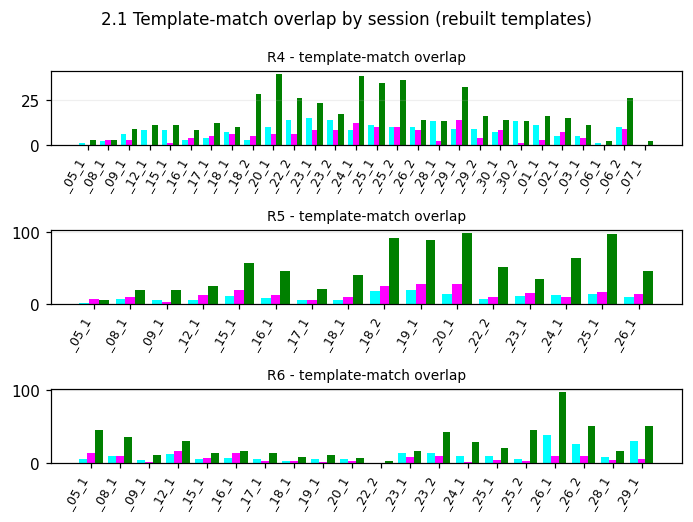

In [221]:
# 2.1 Template-match overlap (SLEAP-only / DANNCE-only / both), one COLUMN per rat.
dual_keys = sorted(DUAL.keys())
_rats = [rt for rt in rats_sorted if any(k[0] == rt for k in dual_keys)]
fig, axes = plt.subplots(len(_rats), 1,
                         #figsize=(max(4.5, 0.7 * max(
                          #   (sum(1 for k in dual_keys if k[0] == rt) for rt in _rats),
                           #  default=1)) * len(_rats), 4),
                         squeeze=False, sharey=False)
for row, rat in enumerate(_rats):
    ax = axes[row, 0]
    _ks = [k for k in dual_keys if k[0] == rat]
    labels = [f'{s[-5:]}' for (_, s) in _ks]
    n_so   = [len(DUAL[k]['sleap_only'])  for k in _ks]
    n_do   = [len(DUAL[k]['dannce_only']) for k in _ks]
    n_both = [len(DUAL[k]['both'])        for k in _ks]
    x = np.arange(len(labels)); w = 0.27
    ax.bar(x - w, n_so,   width=w, color='cyan',    label='SLEAP only')
    ax.bar(x,     n_do,   width=w, color='magenta', label='DANNCE only')
    ax.bar(x + w, n_both, width=w, color='green',   label='both')
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
    ax.set_title(f'{rat} - template-match overlap', fontsize=9)
    ax.grid(axis='y', alpha=0.2)
    if col == 0:
        ax.set_ylabel('# matches'); ax.legend(fontsize=8)
fig.suptitle('2.1 Template-match overlap by session (rebuilt templates)', fontsize=11)
fig.tight_layout(); plt.show()


### 2.2 Calibration health — raw-triangulation reprojection residual per session

**Note (2026-06-25 diagnostic):** `triang_keys_3D.npy` is the output of the
SLEAP→DANNCE corrector network, not the raw triangulation. Reprojecting it
measures corrector pull magnitude, not calibration quality. To actually measure
calibration health we **re-triangulate from `sleap_keys_2D.npy`** per session
and reproject the result. On a verified session, raw-triangulation reprojection
gives ~9 px median residual; the saved (corrector-output) reprojection gives
~60 px. So the metric below is the cleaner one. See
`diagnostics_2026_06_25.md` for the full investigation.


R4/2026_06_05_1: 9.04 px
R4/2026_06_08_1: 8.83 px
R4/2026_06_09_1: 8.89 px
R4/2026_06_12_1: 8.94 px
R4/2026_06_15_1: 9.56 px
R4/2026_06_16_1: 9.88 px
R4/2026_06_17_1: 10.02 px
R4/2026_06_18_1: 9.81 px
R4/2026_06_18_2: 10.08 px
R4/2026_06_20_1: 9.32 px
R4/2026_06_22_2: 9.80 px
R4/2026_06_23_1: 9.40 px
R4/2026_06_23_2: 9.38 px
R4/2026_06_24_1: 9.28 px
R4/2026_06_25_1: 9.24 px
R4/2026_06_25_2: 9.21 px
R4/2026_06_26_2: 9.04 px
R4/2026_06_28_1: 9.51 px
R4/2026_06_29_1: 9.39 px
R4/2026_06_29_2: 9.83 px
R4/2026_06_30_1: 9.85 px
R4/2026_06_30_2: 9.48 px
R4/2026_07_01_1: 10.10 px
R4/2026_07_02_1: 10.83 px
R4/2026_07_03_1: 9.73 px
R4/2026_07_06_1: 10.01 px
R4/2026_07_06_2: 10.27 px
R4/2026_07_07_1: 10.88 px
R5/2026_06_05_1: 9.12 px
R5/2026_06_08_1: 8.64 px
R5/2026_06_09_1: 8.88 px
R5/2026_06_12_1: 9.11 px
R5/2026_06_15_1: 9.41 px
R5/2026_06_16_1: 9.10 px
R5/2026_06_17_1: 9.41 px
R5/2026_06_18_1: 9.45 px
R5/2026_06_18_2: 9.78 px
R5/2026_06_19_1: 9.35 px
R5/2026_06_20_1: 9.07 px
R5/2026_06_22_2: 9

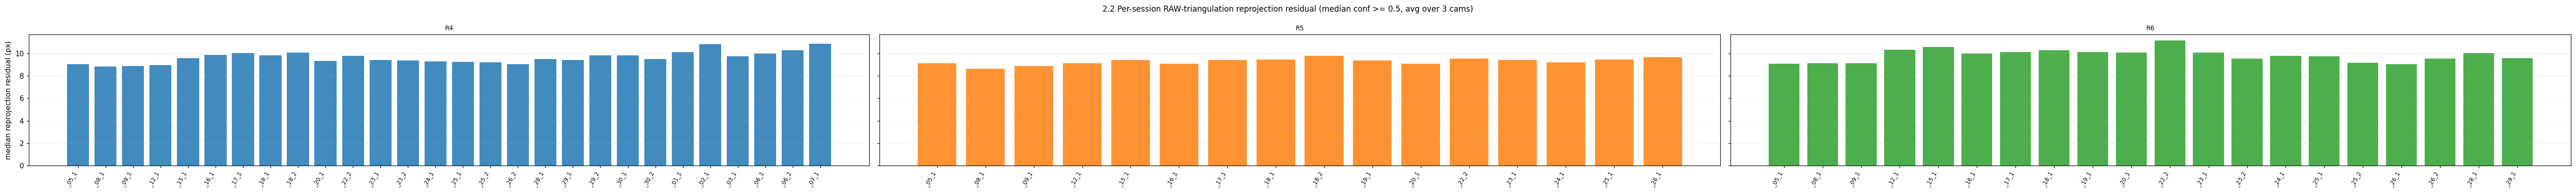

In [222]:
import cv2  # only used by this section

def _undistort_points(pts_2d, K, dist):
    p = pts_2d.reshape(-1, 1, 2).astype(np.float64)
    return cv2.undistortPoints(p, K, np.asarray(dist)).reshape(-1, 2)


def _load_calib_full(cal_dir):
    """Return (P_list, K_list, dist_list) for the 3 cams. P uses identity for K
    because undistortion already applies it (matches campy-CLIRB convention)."""
    P_list, K_list, dist_list = [], [], []
    for cam in range(3):
        p = sio.loadmat(os.path.join(cal_dir, f'hires_cam{cam}_params.mat'),
                         simplify_cells=True)
        K = np.transpose(p['K']); R = np.transpose(p['r']); t = -p['t']
        Rd, Td = p['RDistort'], p['TDistort']
        dist = [Rd[0], Rd[1], Td[0], Td[1]]
        P = np.identity(3) @ np.hstack((R, t.reshape(3, 1)))
        P_list.append(P); K_list.append(K); dist_list.append(dist)
    return P_list, K_list, dist_list


def _triangulate_point(undist_points, P_list):
    A = np.zeros((2 * len(P_list), 4), dtype=np.float64)
    for i, ((x, y), P) in enumerate(zip(undist_points, P_list)):
        A[2 * i]     = x * P[2] - P[0]
        A[2 * i + 1] = y * P[2] - P[1]
    _, _, Vt = np.linalg.svd(A)
    h = Vt[-1]
    if abs(h[3]) < 1e-12:
        return np.full(3, np.nan)
    return (h / h[3])[:3]


def session_raw_reproj_residual(rat, session, conf_thresh=0.5, max_frames=20_000):
    """Re-triangulate sleap_keys_2D from scratch per session, then reproject
    the *raw* 3D back into each camera and compute median pixel error
    (filtered to detections with conf >= conf_thresh). Averages over cams.
    NaN if any required file is missing.
    """
    sleap_dir = os.path.join(DATA_ROOT, rat, session, 'sleap')
    keys2d_path = os.path.join(sleap_dir, 'sleap_keys_2D.npy')
    cal_root = os.path.join(sleap_dir, 'calibration')
    if not (os.path.isfile(keys2d_path) and os.path.isdir(cal_root)):
        return np.nan
    sub = sorted(os.listdir(cal_root))
    if not sub:
        return np.nan
    cal_dir = os.path.join(cal_root, sub[0])
    try:
        # sleap_keys_2D via the local cache (section_cache); (T,3,23,3)=(x,y,conf).
        _c = sc.get_raw_session(rat, session, want_dual=True)
        if _c is None or not _c.get('has_keys2d', False):
            return np.nan
        keys_2d = np.asarray(_c['sleap_keys_2D'])
        P_list, K_list, dist_list = _load_calib_full(cal_dir)
    except Exception:
        return np.nan
    T = min(len(keys_2d), max_frames)
    keys_2d = keys_2d[:T]
    # Re-triangulate frame-by-frame from the saved 2D detections.
    raw_3d = np.full((T, 23, 3), np.nan)
    for t in range(T):
        kp2d = keys_2d[t, :, :, :2]
        undist = np.zeros_like(kp2d)
        for cam in range(3):
            undist[cam] = _undistort_points(kp2d[cam], K_list[cam], dist_list[cam])
        for j in range(23):
            raw_3d[t, j] = _triangulate_point(undist[:, j], P_list)
    # Reproject and compute per-cam median residual.
    per_cam = []
    for cam in range(3):
        proj = project_3d_to_2d_for_camera(raw_3d, cal_dir, camera_idx=cam)
        det  = keys_2d[:, cam, :, :2]
        conf = keys_2d[:, cam, :, 2]
        err = np.linalg.norm(proj - det, axis=-1)
        mask = (conf >= conf_thresh) & np.isfinite(err)
        if mask.any():
            per_cam.append(float(np.median(err[mask])))
    return float(np.mean(per_cam)) if per_cam else np.nan


reproj_rows = []
for (rat, s) in dual_keys:
    res = session_raw_reproj_residual(rat, s)
    print(f'{rat}/{s}: {res:.2f} px' if not np.isnan(res) else f'{rat}/{s}: NaN')
    reproj_rows.append((rat, s, res))
reproj_df = pd.DataFrame(reproj_rows, columns=['rat', 'session', 'reproj_px'])
print()
print(reproj_df.to_string(index=False))

# one COLUMN per rat
_rats = [rt for rt in rats_sorted if (reproj_df['rat'] == rt).any()]
fig, axes = plt.subplots(1, len(_rats),
                         figsize=(max(4.5, 0.6 * int(reproj_df['rat'].value_counts().max()))
                                  * len(_rats), 3.8),
                         squeeze=False, sharey=True)
for col, rat in enumerate(_rats):
    ax = axes[0, col]
    sub = reproj_df[reproj_df['rat'] == rat]
    x = np.arange(len(sub))
    ax.bar(x, sub['reproj_px'].to_numpy(), color=RAT_COLOR.get(rat, '#888'), alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(
        [s[-5:] for s in sub['session']], rotation=60, fontsize=8, ha='right')
    ax.set_title(f'{rat}', fontsize=9)
    ax.grid(axis='y', alpha=0.2)
    if col == 0:
        ax.set_ylabel('median reprojection residual (px)')
fig.suptitle('2.2 Per-session RAW-triangulation reprojection residual '
             '(median conf >= 0.5, avg over 3 cams)', fontsize=11)
fig.tight_layout(); plt.show()


### 2.3 Tracking health — keypoint distance and PC MSE per session

Per-session means of the per-match SLEAP-vs-DANNCE disagreement at the matched
30-frame windows (pooled across SLEAP-only + DANNCE-only + both):

- **Keypoint distance** — mean per-(frame, keypoint) Euclidean distance (mm)
  between the normalized SLEAP and DANNCE skeletons.
- **PC MSE (raw)** — mean per-(frame, PC) squared error in PC space.
- **PC MSE (mean-subtracted)** — same as above but with each modality's
  per-session PC-space mean subtracted first. Removes the rigid SLEAP-vs-DANNCE
  offset that the stale, single-baseline `feature_means` leaves in (see
  `diagnostics_2026_06_25.md`). On the sessions tested, R5/06_20 dropped 17%,
  R6/06_15 dropped 6%, others were flat or worse — informative either way.


rat      session  kp_dist_mean  kp_dist_std  pc_mse_mean  pc_mse_std  pc_mse_dm_mean  pc_mse_dm_std  n_matches
 R4 2026_06_05_1     14.773724     0.832583   466.097778  136.342865      485.591575     146.115116          4
 R4 2026_06_08_1     14.523155     2.914948   571.498709  516.296164      587.320812     506.031376          8
 R4 2026_06_09_1     11.259649     1.872551   655.872996  509.440287      656.695016     489.912797         18
 R4 2026_06_12_1     11.999906     1.836831   541.847240  201.103753      557.910462     205.746434         19
 R4 2026_06_15_1     14.583323     3.164788  1335.094713  961.699691     1369.664647     986.227372         20
 R4 2026_06_16_1     12.277560     1.352219   560.067758  155.411616      557.664354     141.476441         15
 R4 2026_06_17_1     12.433688     1.527423   669.493814  354.912392      667.589273     355.043467         21
 R4 2026_06_18_1     12.947899     2.855872   723.195898  394.239395      717.789420     376.285112         23
 

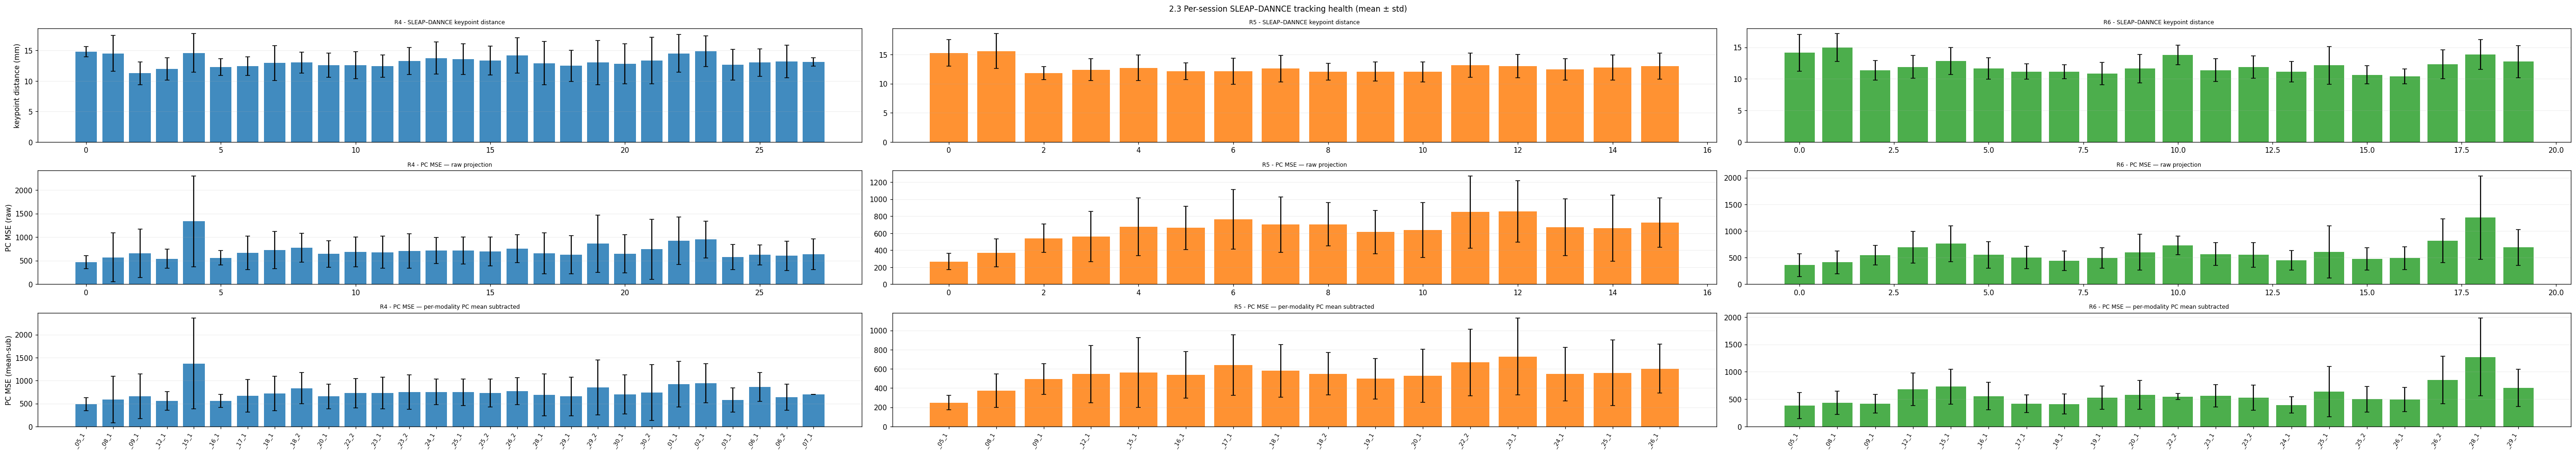

In [223]:
kp_rows = []
for (rat, s) in dual_keys:
    r = DUAL[(rat, s)]
    kp  = r['kp_dist_all']; pc = r['pc_mse_all']
    # PC MSE with per-modality PC-space mean subtraction.
    s_pcs, d_pcs = r['sleap_pcs'], r['dannce_pcs']
    s_mean = s_pcs[:, :N_COMPONENTS].mean(axis=0)
    d_mean = d_pcs[:, :N_COMPONENTS].mean(axis=0)
    all_m = np.concatenate([r['sleap_only'], r['dannce_only'], r['both']]).astype(int)
    pc_mse_demean = []
    for m in all_m:
        a = int(m) - TEMPLATE_LEN + 1; b = int(m) + 1
        if a < 0 or b > min(len(s_pcs), len(d_pcs)):
            continue
        s_seg = s_pcs[a:b, :N_COMPONENTS] - s_mean
        d_seg = d_pcs[a:b, :N_COMPONENTS] - d_mean
        pc_mse_demean.append(((s_seg - d_seg) ** 2).mean())
    pc_dm = np.asarray(pc_mse_demean)
    kp_rows.append((
        rat, s,
        float(kp.mean()) if len(kp) else np.nan, float(kp.std()) if len(kp) else np.nan,
        float(pc.mean()) if len(pc) else np.nan, float(pc.std()) if len(pc) else np.nan,
        float(pc_dm.mean()) if len(pc_dm) else np.nan, float(pc_dm.std()) if len(pc_dm) else np.nan,
        len(kp),
    ))
kp_df = pd.DataFrame(kp_rows, columns=['rat', 'session',
                                        'kp_dist_mean',     'kp_dist_std',
                                        'pc_mse_mean',      'pc_mse_std',
                                        'pc_mse_dm_mean',   'pc_mse_dm_std',
                                        'n_matches'])
print(kp_df.to_string(index=False))

# 3 metric ROWS x one COLUMN per rat
_rats = [rt for rt in rats_sorted if (kp_df['rat'] == rt).any()]
fig, axes = plt.subplots(3, len(_rats),
                         figsize=(max(4.5, 0.6 * int(kp_df['rat'].value_counts().max()))
                                  * len(_rats), 9),
                         squeeze=False, sharex=False)
_metrics = [('kp_dist_mean', 'kp_dist_std', 'keypoint distance (mm)',
             'SLEAP–DANNCE keypoint distance'),
            ('pc_mse_mean', 'pc_mse_std', 'PC MSE (raw)',
             'PC MSE — raw projection'),
            ('pc_mse_dm_mean', 'pc_mse_dm_std', 'PC MSE (mean-sub)',
             'PC MSE — per-modality PC mean subtracted')]
for col, rat in enumerate(_rats):
    sub = kp_df[kp_df['rat'] == rat]
    x = np.arange(len(sub))
    labels = [s[-5:] for s in sub['session']]
    for row, (mcol, scol, ylabel, ttl) in enumerate(_metrics):
        ax = axes[row, col]
        ax.bar(x, sub[mcol].to_numpy(), yerr=sub[scol].to_numpy(),
               color=RAT_COLOR.get(rat, '#888'), capsize=3, alpha=0.85)
        ax.set_title(f'{rat} - {ttl}', fontsize=8)
        ax.grid(axis='y', alpha=0.2)
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == 2:
            ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, fontsize=8, ha='right')
fig.suptitle('2.3 Per-session SLEAP–DANNCE tracking health (mean ± std)', fontsize=11)
fig.tight_layout(); plt.show()
